# Cross-Sectional Machine Learning for Long-Short Equity Selection
### APS1052 group project - full pipeline in one notebook

This notebook runs the whole project end to end: bundled data, feature
engineering, eleven models, a held-out test year, a trading strategy, and two
significance tests. It reads only the CSVs in `data/`, so it runs without
network access or a WRDS account. Those files were pulled once by
`pull_data.py`, which is kept separate on purpose.

### Where each requirement is answered

| Requirement | Section |
|---|---|
| Target: single quantity, asset, frequency | §2 |
| >=15 indicators, >=half not from the target's OHLCV bar | §3–§5 |
| Feature selection; discard the worst 1-2 | §9 |
| >=5 models, >=1 requiring scaled inputs | §13 |
| Manual grid-search CV loop, always `TimeSeriesSplit` | §11, §14 |
| `StandardScaler` / `SelectKBest` inside the pipeline | §13 |
| Neural net: loss, penalties, sample weights | §13 |
| Model regularisation / fine-tuning | §15 |
| Validation metrics: MAE, PF, Spearman rho, directional accuracy by quantile | §16 |
| Test metrics, same four | §16 |
| SHAP feature importance on the test set | §18 |
| Trading strategy in plain English | §19 |
| Test equity curve vs buy-and-hold | §20 |
| White's Reality Check | §22 |
| Monte-Carlo permutation p-value | §23 |
| Robustness: weekly horizon | §24 |
| Sharpe, Profit Factor, CAGR | §21 |

Three parts of the setup are worth reading before the results, because they
change how every later number should be read:

1. §12 estimates what chance alone produces on this panel (about plus/minus
   0.017 rank IC on 20 names) and adds three baselines - a constant, random
   noise, and the single best feature used alone - so the models have
   something to beat.
2. §17 tracks the rank IC through time. When the test result comes in weak,
   that chart is how we tell alpha decay apart from overfitting.
3. §24 repeats the whole exercise on a weekly horizon, which tests both the
   "weekly is less noisy" idea and how much of the daily result is being
   eaten by trading costs.

## §1. Setup and bundled data

Six CSVs, 7.7 MB. Every one written by `pull_data.py` from WRDS.

| File | Contents |
|---|---|
| `prices.csv` | CRSP daily OHLCV, bid/ask, market cap, shares out, SIC — the 20 names plus SPY/QQQ/XLI |
| `option_features.csv` | per name-day: ATM implied vol, 25-delta skew, net gamma exposure, option quoted spread |
| `putcall.csv` | per name-day: put/call volume and open interest |
| `shortint.csv` | semi-monthly short interest, stamped at **publication** date |
| `market.csv` | Fama-French daily factors and VIX |
| `optlink.csv` | the CRSP→OptionMetrics security link actually used |

**Universe.** 20 tickers, hardcoded. Any data-driven selection over the sample would pick names using
information from the end of it and then trade them across it.

**Window.** `2022-01-03 → 2025-08-29`. The end date is OptionMetrics' cutoff.
Running later would leave the five option features empty across the whole test
set. The start is the first date all 20 names trade with warm rolling
windows (WRBY IPO'd 2021-09-29 and is the binding name).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Set the path to where your project folder and 'data/' directory live
PROJECT_PATH = '/content/drive/MyDrive/APS1052_group_project'  # Update to your actual folder path
os.chdir(PROJECT_PATH)

print("Current Working Directory:", os.getcwd())
print("Files in directory:", os.listdir('.'))

Current Working Directory: /content/drive/MyDrive/APS1052_group_project
Files in directory: ['APS1052_final_submission.ipynb', 'data']


In [ ]:
import os, json, time, warnings
import numpy as np
import pandas as pd
!pip install ta-lib
import talib as ta
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, norm

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import (SelectKBest, f_regression,
                                       mutual_info_regression)
from sklearn.linear_model import ElasticNet, Ridge, Lasso
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              HistGradientBoostingRegressor)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.cross_decomposition import PLSRegression
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
RANDOM_STATE = 0
DATA = "data"
FIGS = "figures"
os.makedirs(FIGS, exist_ok=True)

# name universe
MID_CAP   = ["FLEX","TWLO","FTI","CW","NVT","STRL","XPO","EWBC","RGA","EVR"]
SMALL_CAP = ["BLKB","CNXC","CACC","LAZ","EBC","WSBC","WRBY","LQDA","RSI","USLM"]
UNIVERSE  = MID_CAP + SMALL_CAP
BENCHMARKS = ["SPY", "QQQ", "XLI"]

PANEL_START = pd.Timestamp("2022-01-03")
TEST_START  = pd.Timestamp("2024-09-03")
PANEL_END   = pd.Timestamp("2025-08-29")
EMBARGO_DAYS = 5

# CRSP's SIC codes were tried first and bucket
# this universe badly under Fama-French 12 -- XPO (freight), STRL (highway
# construction), USLM (lime), RSI (online casino) and LQDA (biotech) all collapse
# into one "Other" bin, and 8 of 20 land in "Money".
SECTOR = {"FLEX":"InfoTech","TWLO":"InfoTech","BLKB":"InfoTech",
          "CW":"Industrials","NVT":"Industrials","STRL":"Industrials","CNXC":"Industrials",
          "XPO":"Transportation",
          "EWBC":"Financials","RGA":"Financials","EVR":"Financials","CACC":"Financials",
          "LAZ":"Financials","EBC":"Financials","WSBC":"Financials",
          "WRBY":"ConsumerDisc","RSI":"ConsumerDisc",
          "FTI":"Energy","LQDA":"Healthcare","USLM":"Materials"}

def load(name, dates):
    df = pd.read_csv(f"{DATA}/{name}.csv", parse_dates=dates)
    print(f"  {name:18s} {len(df):>7,} rows")
    return df

print("Loading bundled data:")
prices   = load("prices", ["date"])
optfeat  = load("option_features", ["date"])
putcall  = load("putcall", ["date"])
shortint = load("shortint", ["datadate", "pub_date"])
market   = load("market", ["date"])

bench = prices[prices["ticker"].isin(BENCHMARKS)].copy()
px = prices[prices["ticker"].isin(UNIVERSE)].sort_values(["ticker","date"]).reset_index(drop=True)
assert set(px["ticker"]) == set(UNIVERSE)
print(f"\nPanel: {len(px):,} rows | {px['ticker'].nunique()} names | "
      f"{px['date'].min():%Y-%m-%d} → {px['date'].max():%Y-%m-%d}")

Loading bundled data:
  prices              24,480 rows
  option_features     20,000 rows
  putcall             20,002 rows
  shortint             2,033 rows
  market               1,095 rows

Panel: 21,276 rows | 20 names | 2021-06-01 → 2025-08-29


## §2. The prediction target

For stock $i$ on day $t$, predict the **one-day-forward, market-relative log
return**:

$$r_{i,t\to t+1}=\ln\!\left(1+R^{\text{tot}}_{i,t+1}\right),\qquad
y_{i,t}=r_{i,t\to t+1}-\frac{1}{N_t}\sum_{j=1}^{N_t}r_{j,t\to t+1}$$

A **single** quantity, a **regression** target, **daily** frequency, on a panel
of **20 US mid- and small-cap equities**.

Three things make it causal:

1. **The forward shift is per-ticker** — `groupby("ticker").shift(-1)`, never a
   global shift, which would hand ticker A's return to ticker B at every
   boundary between them.
2. **`dlyret` is CRSP's total return**, dividends included — what a portfolio
   actually earns.
3. **The demeaning uses same-day returns only.**

Subtracting the cross-sectional mean makes this a *relative* problem: it strips out whatever the market did that day and leaves only which names beat their peers.

In [ ]:
# compute target: cross-sectionally demeaned next-day log return
px["logret"] = np.log1p(px["dlyret"])
px["fwd_logret"] = px.groupby("ticker")["logret"].shift(-1)
px["cs_mean"] = px.groupby("date")["fwd_logret"].transform("mean")
px["target"] = px["fwd_logret"] - px["cs_mean"]

# check that cross-sectional demeaning worked
chk = px.dropna(subset=["target"]).groupby("date")["target"].mean().abs().max()
print(f"max |daily mean of target|: {chk:.2e}  (must be ~0)")
assert chk < 1e-10, "cross-sectional demeaning failed"
print(f"target sd {px['target'].std():.5f} | kurtosis {px['target'].kurt():.1f}")
print("fat tails -> Huber loss for the neural net, and a winsorised TRAINING target")

max |daily mean of target|: 7.63e-18  (must be ~0)
target sd 0.02318 | kurtosis 32.5
fat tails -> Huber loss for the neural net, and a winsorised TRAINING target


## §3. Bucket A — indicators from the target's own OHLCV bar

TA-Lib oscillators plus two Timothy Masters indicators.The bucket is deliberately capped at 14 to make sure only half of the indicators are TA-Lib related.

| Theme | Features |
|---|---|
| Momentum | `roc_10`, `mom_5`, `mom_21`, `ppo`, `macd_h` |
| Stretch from normal | `rsi_14`, `bb_pos`, `cmma_5`, `cmma_20` |
| Volatility | `atr_c`, `rvol_20`, `adx_14` |
| Volume | `relvol`, `cmf_20` |

Every rolling window runs inside `groupby("ticker")`, so no window spans two
companies. Features are built in **raw** units here; the element-wise transforms
the brief prescribes are applied together in §6, so compliance is auditable in
one place.

In [ ]:
# function to compute bar features for each ticker group
def bar_features(g):
    c, h, l, v = (g["close_adj"].astype(float), g["high_adj"].astype(float),
                  g["low_adj"].astype(float), g["vol_adj"].astype(float))
    # momentum
    g["roc_10"] = ta.ROC(c, timeperiod=10)
    g["mom_5"]  = np.log(c / c.shift(5))
    g["mom_21"] = np.log(c / c.shift(21))
    g["ppo"]    = ta.PPO(c)
    # MACD histogram is in PRICE units
    g["macd_h"] = ta.MACD(c)[2] / c.rolling(63).std()
    # stretch
    g["rsi_14"] = ta.RSI(c, timeperiod=14)
    up, mid, lo = ta.BBANDS(c, timeperiod=20)
    g["bb_pos"] = (c - lo) / (up - lo)
    sma5, sma20 = ta.SMA(c, 5), ta.SMA(c, 20)
    g["cmma_5"]  = (c - sma5) / sma5
    g["cmma_20"] = (c - sma20) / sma20
    # volatility
    g["atr_c"]   = ta.ATR(h, l, c, timeperiod=14) / c
    g["rvol_20"] = np.log(c / c.shift(1)).rolling(20).std() * np.sqrt(252)
    g["adx_14"]  = ta.ADX(h, l, c, timeperiod=14)
    # volume
    g["relvol"] = v / v.rolling(20).mean()
    # Chaikin Money Flow. When high == low the day printed at one price and the
    # multiplier is 0/0 -- the convention is ZERO, not NaN. USLM is thin enough
    # to do this on 23 days, and a NaN there is dragged forward 20 more by the
    # rolling sum, which silently cost it 236 of 913 panel days before it was caught.
    rng_ = (h - l).to_numpy()
    mfm = np.divide(((c - l) - (h - c)).to_numpy(), rng_,
                    out=np.zeros(len(g)), where=rng_ > 0)
    g["cmf_20"] = (pd.Series(mfm, index=g.index) * v).rolling(20).sum() / v.rolling(20).sum()
    return g

BAR = ["roc_10","mom_5","mom_21","ppo","macd_h","rsi_14","bb_pos","cmma_5",
       "cmma_20","atr_c","rvol_20","adx_14","relvol","cmf_20"]
px = px.groupby("ticker", group_keys=False).apply(bar_features)
print(f"Bucket A: {len(BAR)} features from the target's own bar")

Bucket A: 14 features from the target's own bar


## §4. Bucket B - exogenous features

Nothing in this bucket comes from the stock's own price bar. These features are also where we expected the signal to live: price bars are the most mined dataset in finance, while things like dealer gamma positioning and lagged short interest are not.

**Notice**: For short interest, compustat stamps each figure with `datadate`, the FINRA settlement date, but the number only becomes public about eight business days later. Forward-filling from `datadate` would give the model a number that did not exist yet at the time, and in a backtest that kind of mistake looks exactly like skill. The merge below therefore keys on the publication date, and an assertion checks it.

In [ ]:
# The backtests in §19/§24 charge costs off the RAW quoted spread, so keep a
# copy now: §6's element-wise pass overwrites px["stock_spread"] with
# log1p(spread) and would quietly feed the cost model a transformed feature.
# Three CRSP quotes are crossed (ask < bid); a negative cost is nonsense, so
# floor them at zero.
px["spread_raw"] = px["stock_spread"].clip(lower=0.0)

# ---- options flow ---------------------------------------------------------
pc = putcall.copy()
pc["pc_vol"] = pc["put_vol"] / pc["call_vol"].replace(0, np.nan)
pc["pc_oi"]  = pc["put_oi"]  / pc["call_oi"].replace(0, np.nan)
pc["opt_vol_tot"] = pc["put_vol"] + pc["call_vol"]
px = px.merge(pc[["ticker","date","pc_vol","pc_oi","opt_vol_tot"]], on=["ticker","date"], how="left")
px["optvol_ratio"] = px["opt_vol_tot"] / px["vol_adj"].replace(0, np.nan)

# ---- implied vol surface, gamma, option liquidity -------------------------
px = px.merge(optfeat[["ticker","date","iv_30d","iv_skew","gex","opt_spread"]],
              on=["ticker","date"], how="left")
# Raw gamma scales with company size, so cross-sectionally it would rank TWLO
# above USLM for reasons unrelated to hedging pressure. dlycap is in $thousands.
px["gex_norm"] = px["gex"] / (px["dlycap"] * 1_000.0)
# Variance risk premium: what options CHARGE for vol minus what the stock DELIVERS.
px["iv_rv"] = px["iv_30d"] - px["rvol_20"]

# ---- short interest, merged as-of PUBLICATION date ------------------------
si = shortint.dropna(subset=["ticker","pub_date"]).sort_values("pub_date").copy()
si["d_si"] = si.groupby("ticker")["shortintadj"].pct_change()
px = pd.merge_asof(px.sort_values("date"),
                   si[["ticker","pub_date","shortintadj","d_si"]],
                   left_on="date", right_on="pub_date", by="ticker",
                   direction="backward").sort_values(["ticker","date"]).reset_index(drop=True)
adv20 = px.groupby("ticker")["vol_adj"].transform(lambda s: s.rolling(20).mean())
px["dtc"]    = px["shortintadj"] / adv20.replace(0, np.nan)
px["si_pct"] = px["shortintadj"] / (px["shrout"] * 1_000.0)

stale = (px["date"] - px["pub_date"]).dt.days.dropna()
assert (stale >= 0).all(), "as-of merge used an unpublished figure"
print(f"[ok] short interest: every value already public when used "
      f"(median age {stale.median():.0f}d, max {stale.max():.0f}d)")

# ---- risk model and peer-relative strength --------------------------------
px = px.merge(market[["date","mktrf","umd","rf","vix"]], on="date", how="left")
px[["mktrf","umd","rf","vix"]] = px.groupby("ticker")[["mktrf","umd","rf","vix"]].ffill()
px["exret"] = px["logret"] - px["rf"]
mkt21 = market.set_index("date")["mktrf"].sort_index().rolling(21).sum().rename("mkt_21")
px = px.merge(mkt21, left_on="date", right_index=True, how="left")
px["mkt_21"] = px.groupby("ticker")["mkt_21"].ffill()

def risk_features(g):
    m, u, e = g["mktrf"], g["umd"], g["exret"]
    var_m = m.rolling(60).var()
    g["beta_60"] = e.rolling(60).cov(m) / var_m.replace(0, np.nan)
    # Residual sd from the SAME 60-day regression. A 60-day rolling sd of the
    # residual series would need 120 observations to warm, because the residual
    # is itself NaN until beta exists -- that cost WRBY its first 53 panel days.
    # For a single-regressor OLS, residual variance = Var(y) - beta^2 Var(x).
    g["idio_vol_60"] = np.sqrt((e.rolling(60).var() - g["beta_60"]**2 * var_m).clip(lower=0)) * np.sqrt(252)
    g["beta_umd_60"] = e.rolling(60).cov(u) / u.rolling(60).var().replace(0, np.nan)
    g["ret_21"] = np.log(g["close_adj"] / g["close_adj"].shift(21))
    g["resid_mom_21"] = g["ret_21"] - g["beta_60"] * g["mkt_21"]
    return g

px = px.groupby("ticker", group_keys=False).apply(risk_features)

px["sector"] = px["ticker"].map(SECTOR)
grp_n  = px.groupby(["date","sector"])["ret_21"].transform("size")
grp_mu = px.groupby(["date","sector"])["ret_21"].transform("mean")
px["sect_rel_21"] = np.where(grp_n > 1, px["ret_21"] - grp_mu, np.nan)

# Market-wide: identical for every name on a date, so cross-sectional variance
# is ZERO and neither can rank one stock above another on its own. Kept as
# interaction terms and scaled through TIME rather than across the cross-section.
px["vix_chg5"]  = px.groupby("ticker")["vix"].transform(lambda s: s - s.shift(5))
px["vix_level"] = px["vix"]

OPT     = ["pc_vol","pc_oi","optvol_ratio","iv_30d","iv_skew","iv_rv","gex_norm","opt_spread"]
LIQ_SI  = ["stock_spread","dtc","si_pct","d_si"]
RISK    = ["beta_60","idio_vol_60","beta_umd_60","sect_rel_21","resid_mom_21"]
MARKET_WIDE = ["vix_chg5","vix_level"]
EXOG = OPT + LIQ_SI + RISK + MARKET_WIDE
print(f"Bucket B: {len(EXOG)} exogenous features")

[ok] short interest: every value already public when used (median age 7d, max 17d)
Bucket B: 19 exogenous features


A `"relative strength vs XLI"` feature was tried first (21-day return minus the
XLI ETF's 21-day return) and turns out to be **exactly collinear with plain
momentum** once standardised, as shown below. This is because `xli_21` is market-wide, so subtracting it shifts every name on a date by the same constant, and a per-day z-score removes exactly that.

**Any feature of the form "name-specific quantity minus market-wide quantity" is
a no-op under cross-sectional standardisation.** Beta-adjusting instead makes
the subtraction name-specific, because beta varies across names — which is what
`resid_mom_21` does.

In [ ]:
# Test: the two ways of computing relative strength are identical
xli = bench[bench["ticker"] == "XLI"][["date","close_adj"]].sort_values("date")
xli["xli_21"] = np.log(xli["close_adj"] / xli["close_adj"].shift(21))
_tmp = px.merge(xli[["date","xli_21"]], on="date", how="left")
_naive = _tmp["ret_21"] - _tmp["xli_21"]
def _z(s, d):
    g = s.groupby(d); return (s - g.transform("mean")) / g.transform("std")
_chk = pd.concat([_z(_tmp["ret_21"], _tmp["date"]), _z(_naive, _tmp["date"])], axis=1).dropna()
print(f"corr(z_mom_21, z_rel_str_xli) = {_chk.iloc[:,0].corr(_chk.iloc[:,1]):.12f}   "
      f"max|diff| = {(_chk.iloc[:,0]-_chk.iloc[:,1]).abs().max():.1e}")
print("-> identical. Demonstrated rather than asserted.")

corr(z_mom_21, z_rel_str_xli) = 1.000000000000   max|diff| = 1.3e-15
-> identical. Demonstrated rather than asserted.


## §5. Bucket C — the calendar block

Selected or dropped **as a unit**, never individually. Day-of-week dummies form a set.

`month_sin`/`month_cos` place the month on a circle so December sits adjacent to
January; a raw integer would treat those two as maximally far apart.
`days_to_holiday` is derived from the trading calendar itself — any weekday
absent from the CRSP date index *is* a market holiday, which catches Good Friday
and correctly ignores Columbus Day.

In [ ]:
#convert calendar features to dummies and sin/cos transforms
dow = pd.get_dummies(px["date"].dt.dayofweek, prefix="dow", drop_first=True, dtype=float)
px = pd.concat([px, dow], axis=1)
px["month_sin"] = np.sin(2*np.pi*px["date"].dt.month/12.0)
px["month_cos"] = np.cos(2*np.pi*px["date"].dt.month/12.0)

# Market holidays are not in the panel, so infer them from the gaps in the
# trading calendar. The next holiday is the first date in the inferred list
# that is >= the current date. The number of days to that holiday is clipped
# to [0,60] because the model is not expected to extrapolate beyond that.
trading_days = pd.DatetimeIndex(sorted(px["date"].unique()))
holidays = pd.bdate_range(trading_days.min(), trading_days.max()).difference(trading_days)
hol = np.array(sorted(holidays.values))
nxt = np.searchsorted(hol, px["date"].values, side="left")
px["days_to_holiday"] = np.clip(
    np.where(nxt < len(hol), (hol[np.clip(nxt,0,len(hol)-1)] - px["date"].values)/np.timedelta64(1,"D"), np.nan),
    0, 60)

CAL = sorted([c for c in px.columns if c.startswith("dow_")]) + \
      ["month_sin","month_cos","days_to_holiday"]
print(f"Bucket C: {len(CAL)} calendar features | {len(holidays)} market holidays inferred")

Bucket C: 7 calendar features | 41 market holidays inferred


## §6. Stage 1 — element-wise transforms

Each entry maps a raw feature to a pure element-wise function in a single cell.

- **Bounded oscillators** (RSI, ADX) are already stationary — recentre and rescale to ≈$[-1,1]$.
- **Percentage indicators** (PPO, ROC) divide by 100.
- **Positive, multiplicatively-growing** quantities take a log first (`log1p` where zero is reachable).
- **Signed, unbounded** quantities take `asinh`, which is ≈identity near zero, ≈log in the tails, and accepts negatives.
- **Beta** uses the brief's own $\operatorname{asinh}(\beta-1)$, centring a market-neutral name at zero.

`iv_rv` is deliberately computed from the **raw** implied and realised vols in
§4, before either is transformed — the premium is only meaningful as a
difference of two quantities in the same units.

In [ ]:
# ---- feature transformations ------------------------------------------------
STAGE1 = {
    "rsi_14": lambda s: (s-50.)/50.,   "adx_14": lambda s: s/100.,
    "ppo":    lambda s: s/100.,        "roc_10": lambda s: s/100.,
    "bb_pos": lambda s: 2.*s - 1.,                       # the brief's [-1,1] form
    "atr_c": np.log1p, "rvol_20": np.log1p, "relvol": np.log1p,
    "iv_30d": np.log1p, "opt_spread": np.log1p, "stock_spread": np.log1p,
    "dtc": np.log1p, "si_pct": np.log1p, "pc_vol": np.log1p, "pc_oi": np.log1p,
    "optvol_ratio": np.log1p, "idio_vol_60": np.log1p, "vix_level": np.log,
    "macd_h": np.arcsinh, "cmma_5": np.arcsinh, "cmma_20": np.arcsinh,
    "iv_skew": np.arcsinh, "iv_rv": np.arcsinh, "gex_norm": np.arcsinh,
    "d_si": np.arcsinh, "beta_umd_60": np.arcsinh,
    "beta_60": lambda s: np.arcsinh(s - 1.0),            # the brief's beta form
    "mom_5": lambda s: s, "mom_21": lambda s: s, "cmf_20": lambda s: s,
    "sect_rel_21": lambda s: s, "resid_mom_21": lambda s: s, "vix_chg5": lambda s: s,
}
ALL_FEATURES = BAR + EXOG

# assurance that every feature in the panel has a transformation function
assert set(ALL_FEATURES) <= set(STAGE1), set(ALL_FEATURES) - set(STAGE1)
for col, fn in STAGE1.items():
    px[col] = fn(px[col].astype(float))

n_tot, n_non_bar = len(ALL_FEATURES)+len(CAL), len(EXOG)+len(CAL)
print(f"Candidates: {n_tot}  ({len(BAR)} bar + {len(EXOG)} exogenous + {len(CAL)} calendar)")
print(f"NOT based on the target's OHLCV bar: {n_non_bar}/{n_tot} = {n_non_bar/n_tot:.0%} (>50%)")
print(f"excluding the calendar block:        {len(EXOG)}/{len(ALL_FEATURES)} = {len(EXOG)/len(ALL_FEATURES):.0%}")

Candidates: 40  (14 bar + 19 exogenous + 7 calendar)
NOT based on the target's OHLCV bar: 26/40 = 65% (>50%)
excluding the calendar block:        19/33 = 58%


## §7. Stage 2 — causal standardisation

Two scalings, because two kinds of feature.

1. **Name-specific features get a per-day cross-sectional z-score.** So each value
becomes relative to their other 19 peers. It touches only
same-day data, so it *cannot* look ahead — no training statistics leak into the
test set. `StandardScaler` is also the right scaling for the problem: the target is a cross-sectional quantity, so the features should be too.

    With only 20 names the daily mean and sd are themselves noisy and one outlier drags both, so values are **winsorised at ±3 robust sigma before standardising**.

2. **Market-wide features get an expanding-window time-series z-score**, since a
cross-sectional z-score is $0/0$ for a series identical across all 20 names. An
expanding window at date $t$ sees only dates $\le t$, so it stays causal.

In [ ]:
XS = [f for f in ALL_FEATURES if f not in MARKET_WIDE]

# Winsorise each feature in the cross-section, then z-score across the cross-section.
def winsorise(s, k=3.0):
    med = s.median(); mad = (s - med).abs().median() * 1.4826
    return s if (not np.isfinite(mad) or mad == 0) else s.clip(med-k*mad, med+k*mad)

for f in XS:
    w  = px.groupby("date")[f].transform(winsorise)
    mu = w.groupby(px["date"]).transform("mean")
    sd = w.groupby(px["date"]).transform("std")
    px[f"z_{f}"] = (w - mu) / sd.replace(0, np.nan)

for f in MARKET_WIDE:
    s = px.groupby("date")[f].first().sort_index()
    z = (s - s.expanding(60).mean()) / s.expanding(60).std().replace(0, np.nan)
    px = px.merge(z.clip(-5,5).rename(f"z_{f}"), left_on="date", right_index=True, how="left")

daily = [np.nanmax(np.abs(px.groupby("date")[f"z_{f}"].mean().values)) for f in XS]
print(f"max |daily mean| across cross-sectional features: {np.nanmax(daily):.2e} (must be ~0)")
assert np.nanmax(daily) < 1e-6, "cross-sectional standardisation did not centre"
print("[ok] every cross-sectionally scaled feature averages exactly zero each day")

max |daily mean| across cross-sectional features: 9.22e-16 (must be ~0)
[ok] every cross-sectionally scaled feature averages exactly zero each day


## §8. Burn-in, train/test split, and the embargo

Rolling windows need history before they mean anything, so every row before
`PANEL_START` is dropped.

The final 12 months are held out. Between train and test sits a **5-business-day
embargo**: without it the last training row's target looks one day into the test
period, and 60-day windows straddle the boundary.

In [ ]:
DENSE  = [f for f in BAR + RISK + MARKET_WIDE if f != "sect_rel_21"]    #T§19/§24 backtests use only the dense set.
SPARSE = [f for f in ALL_FEATURES if f not in DENSE]

panel = px[(px["date"] >= PANEL_START) & (px["date"] <= PANEL_END)].copy()
panel = panel.dropna(subset=["target"] + [f"z_{f}" for f in DENSE])

per_day = panel.groupby("date")["ticker"].nunique()
print(f"Panel: {len(panel):,} rows | cross-section sizes {per_day.value_counts().to_dict()}")
print(f"Balanced days (all 20 names): {(per_day == 20).mean():.1%} of {len(per_day)}")

#embargo: drop the last EMBARGO_DAYS of the training set to avoid look-ahead bias
embargo_end = TEST_START - pd.tseries.offsets.BDay(EMBARGO_DAYS)
train = panel[panel["date"] < embargo_end].copy()
test  = panel[panel["date"] >= TEST_START].copy()
gap   = panel[(panel["date"] >= embargo_end) & (panel["date"] < TEST_START)]
print(f"\n  train   {train.date.min():%Y-%m-%d} → {train.date.max():%Y-%m-%d}  {len(train):>6,} rows")
print(f"  embargo {embargo_end:%Y-%m-%d} → {TEST_START:%Y-%m-%d}  {len(gap):>6,} rows dropped")
print(f"  test    {test.date.min():%Y-%m-%d} → {test.date.max():%Y-%m-%d}  {len(test):>6,} rows")
assert train.date.max() + pd.Timedelta(days=1) < test.date.min()
print("\n[ok] embargo holds even after the target's own one-day look-ahead")

Panel: 18,340 rows | cross-section sizes {20: 917}
Balanced days (all 20 names): 100.0% of 917

  train   2022-01-03 → 2024-08-26  13,300 rows
  embargo 2024-08-27 → 2024-09-03      80 rows dropped
  test    2024-09-03 → 2025-08-28   4,960 rows

[ok] embargo holds even after the target's own one-day look-ahead


## §9. Feature selection — Profit Factor, Alpha, Mutual Information

To perform a univariate Profit-Factor screen, the metric is implemented as:
$\text{PF}=\sum\text{gains}/\sum|\text{losses}|$ for a sign-based signal, plus a
Masters-style annualised alpha and mutual information as a non-linear
cross-check. A **Benjamini–Hochberg** correction is applied because ~30 features
are tested simultaneously.

Everything is computed on the **training split only**.

**Two features are exempt from the screen.** A market-wide feature takes the
same value for all 20 names, so $\text{sign}(x)$ is constant within a day and
that day contributes $s_t\sum_i y_{i,t}$ — which is zero, because the target is
demeaned. Gains and losses cancel identically and the Profit Factor is
**exactly 1.0000**. That is the screen being structurally blind, not a
measurement of no edge.

In [ ]:
# ---- univariate ranking of features -----------------------------------------
def profit_factor_of(sig, y):
    r = np.sign(sig) * y; r = r[np.isfinite(r)]
    g_, l_ = r[r>0].sum(), -r[r<0].sum()
    return g_/l_ if l_ > 0 else np.nan

#cross-sectional univariate ranking of features on the training split only
CANDIDATES = [f for f in ALL_FEATURES if f not in MARKET_WIDE]
rows = []
for f in CANDIDATES:
    sub = train[[f"z_{f}","target"]].dropna()
    if len(sub) < 100: continue
    sig, y = sub[f"z_{f}"].values, sub["target"].values
    r = np.sign(sig)*y
    se = r.std(ddof=1)/np.sqrt(len(r)); t = r.mean()/se if se>0 else 0.0
    rows.append({"Feature": f, "Bucket": "bar" if f in BAR else "exogenous",
                 "PF": profit_factor_of(sig,y), "Alpha_ann": r.mean()*252.,
                 "T_stat": t, "P_value": 2*(1-norm.cdf(abs(t))),
                 "MI": mutual_info_regression(sub[[f"z_{f}"]], y, random_state=0)[0]})
rank = pd.DataFrame(rows).sort_values("PF", ascending=False).reset_index(drop=True)

# Benjamini-Hochberg FDR control at 10% level
order, m, ok, prev = rank.sort_values("P_value").index, len(rank), {}, True
for i, idx in enumerate(order, 1):
    prev = prev and (rank.loc[idx,"P_value"] <= i/m*0.10); ok[idx] = prev
rank["BH_sig_10pct"] = rank.index.map(ok)

print("Univariate ranking, TRAINING SPLIT ONLY:\n")
print(rank.round(4).to_string(index=False))
print(f"\nBH-significant at 10% FDR: {int(rank['BH_sig_10pct'].sum())} of {len(rank)}")
for f in MARKET_WIDE:
    sub = train[[f"z_{f}","target"]].dropna()
    print(f"  {f:12s} PF = {profit_factor_of(sub[f'z_{f}'].values, sub['target'].values):.10f}"
          "   <- identically 1.0 by construction, hence exempt")

Univariate ranking, TRAINING SPLIT ONLY:

     Feature    Bucket     PF  Alpha_ann  T_stat  P_value     MI  BH_sig_10pct
 beta_umd_60 exogenous 1.0655     0.1231  2.3486   0.0188 0.0139         False
  opt_spread exogenous 1.0509     0.0982  1.7111   0.0871 0.0000         False
        d_si exogenous 1.0472     0.0896  1.7095   0.0874 0.0012         False
      cmf_20       bar 1.0359     0.0685  1.3065   0.1914 0.0000         False
stock_spread exogenous 1.0321     0.0613  1.1689   0.2425 0.0024         False
 sect_rel_21 exogenous 1.0263     0.0471  0.8930   0.3719 0.0000         False
      rsi_14       bar 1.0166     0.0319  0.6082   0.5431 0.0020         False
      relvol       bar 1.0129     0.0249  0.4739   0.6356 0.0043         False
      roc_10       bar 1.0108     0.0208  0.3968   0.6915 0.0126         False
resid_mom_21 exogenous 1.0075     0.0146  0.2786   0.7805 0.0075         False
       pc_oi exogenous 1.0005     0.0010  0.0177   0.9859 0.0104         False
      mom_

### Dropping low-performing features

The drop is made on **distance from 1.0**, not on the raw Profit Factor. The
screen sees only a feature's *sign*, so a feature at 0.92 is not weak — it is a
working signal pointing the other way, which any model downstream can flip.
Short-term reversal (`mom_5`) is the textbook case. Ranking on the raw value
would discard the strongest signals in the set and keep the ones carrying no
information at all.

In [ ]:
N_DROP = 2
rank["edge"] = (rank["PF"] - 1.0).abs()
dropped = rank.sort_values("edge").head(N_DROP)["Feature"].tolist()
KEPT = [f for f in ALL_FEATURES if f not in dropped]
FEATURES = [f"z_{f}" for f in KEPT] + CAL

#drop the two features that are closest to PF = 1.0, i.e. have the weakest univariate signal, and are not in the calendar block
print(f"Dropped (closest to PF = 1.0, no edge in either direction): {dropped}")
kept_exog = [f for f in KEPT if f in EXOG]
n_tot, n_non_bar = len(KEPT)+len(CAL), len(kept_exog)+len(CAL)
print(f"Selected: {len(FEATURES)} columns | not from the target's bar: "
      f"{n_non_bar}/{n_tot} = {n_non_bar/n_tot:.0%}")
assert n_non_bar/n_tot >= 0.5
print("\nStrongest signals by |PF-1| (sign shows the DIRECTION of the edge):")
for _, r_ in rank.sort_values("edge", ascending=False).head(6).iterrows():
    print(f"   {r_['Feature']:14s} PF {r_['PF']:.4f}  t {r_['T_stat']:+.2f}  -> "
          f"{'long-high' if r_['PF']>1 else 'long-LOW (reversal)'}")

X_tr, y_tr, d_tr = train[FEATURES], train["target"].values, train["date"].values
X_te, y_te, d_te = test[FEATURES],  test["target"].values,  test["date"].values
# winsorise at 5 sd to reduce the impact of extreme outliers on the training
WINSOR_SD = 5.0; _sd = y_tr.std()
y_tr_w = np.clip(y_tr, -WINSOR_SD*_sd, WINSOR_SD*_sd)
print(f"\nTraining target winsorised at ±{WINSOR_SD} sd: "
      f"{int((np.abs(y_tr)>WINSOR_SD*_sd).sum())} rows clipped "
      f"({100*(np.abs(y_tr)>WINSOR_SD*_sd).mean():.2f}%), kurtosis "
      f"{pd.Series(y_tr).kurt():.1f} → {pd.Series(y_tr_w).kurt():.1f}")
print("Every metric, and the entire test set, uses the RAW target.")

Dropped (closest to PF = 1.0, no edge in either direction): ['mom_21', 'pc_oi']
Selected: 38 columns | not from the target's bar: 25/38 = 66%

Strongest signals by |PF-1| (sign shows the DIRECTION of the edge):
   iv_skew        PF 0.9161  t -3.03  -> long-LOW (reversal)
   beta_umd_60    PF 1.0655  t +2.35  -> long-high
   optvol_ratio   PF 0.9381  t -2.28  -> long-LOW (reversal)
   beta_60        PF 0.9446  t -2.11  -> long-LOW (reversal)
   opt_spread     PF 1.0509  t +1.71  -> long-high
   atr_c          PF 0.9525  t -1.80  -> long-LOW (reversal)

Training target winsorised at ±5.0 sd: 52 rows clipped (0.39%), kurtosis 36.5 → 5.6
Every metric, and the entire test set, uses the RAW target.


## §10. The four required metrics

These follow `YieldCurveForecastPmdarimaExogenous_ONESTEPAHEAD_DGS10_d0_d1.ipynb`(cells 32–33), with one necessary adaptation. The reference target is a yield *level*, so it takes `np.diff()` to recover the direction of change. Ours is already a one-day log return — it *is* the change. Differencing would measure the change in the return rather than its direction. So `sign(target)` is used directly.

**Rank IC is computed per day, then averaged — never pooled.** With 20 names per day, pooling would inflate the t-statistic by roughly $\sqrt{20}$.

**A day on which a model gives no ordering scores zero, and is not skipped.**
Skipping silently rewards degeneracy: a model that collapses to a constant on 80% of days would be judged only on the 20% where it did something. This is not hypothetical — an over-regularised ElasticNet won an earlier comparison exactly that way.

In [ ]:
# ---- evaluation metrics ------------------------------------------------------
# MAE: mean absolute error, in the same units as the target (log return)
def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true,float) - np.asarray(y_pred,float))))

# Profit factor: sum of gains / sum of losses, in the same units as the target (log return)
def profit_factor(returns):
    r = np.asarray(returns,float); r = r[np.isfinite(r)]
    g_, l_ = r[r>0].sum(), -r[r<0].sum()
    return np.inf if l_==0 and g_>0 else (np.nan if l_==0 else float(g_/l_))

# directional accuracy: % of times the model correctly predicts the sign of the target
def signal_profit_factor(y_true, y_pred):
    return profit_factor(np.sign(np.asarray(y_pred,float)) * np.asarray(y_true,float))

# Spearman rank correlation of the model's predictions with the target, averaged across days
def rank_ic(y_true, y_pred, dates):
    """Mean daily Spearman -> (ic, t, n_days, n_days_with_no_ordering)."""
    df = pd.DataFrame({"d":np.asarray(dates),"y":np.asarray(y_true,float),
                       "p":np.asarray(y_pred,float)}).dropna()
    ics, degenerate = [], 0
    for _, g in df.groupby("d"):
        if len(g) < 3 or g.y.nunique() < 2: continue
        if g.p.nunique() < 2: ics.append(0.0); degenerate += 1; continue
        ic = spearmanr(g.p, g.y).statistic
        ics.append(ic if np.isfinite(ic) else 0.0)
    ics = np.asarray(ics)
    if len(ics) < 2: return np.nan, np.nan, len(ics), degenerate
    return (float(ics.mean()),
            float(ics.mean()/(ics.std(ddof=1)/np.sqrt(len(ics)))), len(ics), degenerate)

# daily Spearman rank correlation of the model's predictions with the target, returned as a pd.Series indexed by date
def daily_ic_series(y_true, y_pred, dates):
    df = pd.DataFrame({"d":np.asarray(dates),"y":np.asarray(y_true,float),
                       "p":np.asarray(y_pred,float)}).dropna()
    out = {}
    for d_, g in df.groupby("d"):
        if len(g) < 3 or g.y.nunique() < 2: continue
        out[d_] = 0.0 if g.p.nunique() < 2 else spearmanr(g.p, g.y).statistic
    return pd.Series(out).sort_index()

# directional accuracy by absolute-move quantile, returned as a pd.DataFrame indexed by quantile
def directional_accuracy_by_quantile(y_true, y_pred, q=5):
    df = pd.DataFrame({"true":np.asarray(y_true,float),"pred":np.asarray(y_pred,float)}).dropna()
    df["correct"]  = np.sign(df["true"]) == np.sign(df["pred"])
    df["abs_move"] = df["true"].abs()
    df["q"] = pd.qcut(df["abs_move"], q=q, labels=False, duplicates="drop")
    names = ["Q1 (tiny)","Q2","Q3","Q4","Q5 (large)"][:q]
    df["q"] = df["q"].map(dict(zip(sorted(df["q"].dropna().unique()), names)))
    out = (df.groupby("q", observed=True)["correct"].agg(["mean","count"])
             .rename(columns={"mean":"Hit Rate","count":"N"}))
    out["% of Total"] = (out["N"]/len(df)*100).round(1)
    out["Naive"] = df.groupby("q", observed=True)["true"].apply(
        lambda g: max((g>0).sum(),(g<0).sum())/len(g))
    out["Skill"] = out["Hit Rate"] - out["Naive"]
    out["Mean |move|"] = df.groupby("q", observed=True)["abs_move"].mean()
    return out.reindex([n for n in names if n in out.index])

# Report all metrics
def report(y_true, y_pred, dates, label="", verbose=True):
    ic, t, nd, ndeg = rank_ic(y_true, y_pred, dates)
    y, p = np.asarray(y_true,float), np.asarray(y_pred,float)
    n_up, n_dn = int((y>0).sum()), int((y<0).sum())
    naive = max(n_up,n_dn)/len(y)*100
    hit = float((np.sign(y)==np.sign(p)).sum())/len(y)*100
    res = {"label":label,"MAE":mae(y,p),"ProfitFactor":signal_profit_factor(y,p),
           "RankIC":ic,"RankIC_t":t,"n_days":nd,"DegenDays":ndeg,
           "DirAcc":hit,"NaiveDirAcc":naive,"Skill":hit-naive}
    if verbose:
        print(f"\n{'='*68}\n{label}\n{'='*68}")
        print(f"  Mean absolute error : {res['MAE']:.6f}")
        print(f"  Profit Factor       : {res['ProfitFactor']:.4f}")
        print(f"  Spearman Rank IC    : {ic:+.4f}  (t = {t:+.2f} over {nd} days"
              + (f", {ndeg} with no ordering)" if ndeg else ")"))
        print(f"  Naive hit rate      : {naive:.2f}%   Model hit rate: {hit:.2f}%")
        print(f"  Skill vs naive      : {hit-naive:+.2f} pct points")
        print("\n  Directional accuracy by absolute-move quintile:")
        print(directional_accuracy_by_quantile(y,p).to_string(float_format=lambda x:f"{x:8.4f}"))
    return res
print("Metrics defined: MAE, Profit Factor, Spearman rank IC, directional accuracy by quantile.")

Metrics defined: MAE, Profit Factor, Spearman rank IC, directional accuracy by quantile.


## §11. Cross-validation — `TimeSeriesSplit` over dates

We need to apply `TimeSeriesSplit` to the panel. Yet sklearn's row-wise version is quietly wrong: with 20 stocks per day it puts the same date on both sides of a fold boundary, so the model trains on 12 names from a day and validates on the other 8 — having already seen that day's cross-section, including the mean the target was demeaned by. Every score
inflates.

This is the same expanding-window scheme applied to whole **dates**, with an
embargo after each training block.

In [ ]:
class DateGroupedTimeSeriesSplit:
    """Expanding-window TimeSeriesSplit whose folds break between whole days."""
    def __init__(self, n_splits=5, embargo=5):
        self.n_splits, self.embargo = n_splits, embargo
    def get_n_splits(self, X=None, y=None, groups=None): return self.n_splits
    def split(self, X, y=None, groups=None):
        g = pd.Series(np.asarray(groups)); udates = np.array(sorted(g.unique()))
        n, idx = len(udates), np.arange(len(g)); fold = n // (self.n_splits + 1)
        for k in range(self.n_splits):
            tr_end = fold*(k+1); va_beg = tr_end + self.embargo
            va_end = min(va_beg + fold, n)
            if va_beg >= n: break
            tr = idx[g.isin(udates[:tr_end]).to_numpy()]
            va = idx[g.isin(udates[va_beg:va_end]).to_numpy()]
            if len(tr) and len(va): yield tr, va

CV = DateGroupedTimeSeriesSplit(n_splits=5, embargo=5)
print("Fold structure (expanding window, 5-day embargo):")
for k,(tr,va) in enumerate(CV.split(X_tr, y_tr, groups=d_tr)):
    td, vd = pd.Series(d_tr[tr]), pd.Series(d_tr[va])
    assert td.max() < vd.min()
    print(f"  fold {k}: train {len(tr):>6,} / {td.nunique():>3}d  →  "
          f"val {len(va):>5,} / {vd.nunique():>3}d   gap {(vd.min()-td.max()).days}d")
print("\n[ok] every fold boundary falls between whole trading days")

Fold structure (expanding window, 5-day embargo):
  fold 0: train  2,200 / 110d  →  val 2,200 / 110d   gap 8d
  fold 1: train  4,400 / 220d  →  val 2,200 / 110d   gap 8d
  fold 2: train  6,600 / 330d  →  val 2,200 / 110d   gap 8d
  fold 3: train  8,800 / 440d  →  val 2,200 / 110d   gap 8d
  fold 4: train 11,000 / 550d  →  val 2,200 / 110d   gap 8d

[ok] every fold boundary falls between whole trading days


## §12. Chance Testing: empirical null and three baselines

1. **the null**. Predictions are shuffled within each day, which keeps the
panel shape (same days, same cross-section size, same target distribution)
and destroys only the ordering. For a cross-sectional ranking score, that is
the right thing to randomise.

2. **three baselines**

- **`ZeroPredictor`** predicts a constant. It gets one of the best MAE
  scores in the whole study while being useless to trade, which is the
  clearest argument against judging these models by MAE.
- **`RandomPredictor`** draws noise.
- **`BestSingleFeature`** uses the strongest single feature, chosen inside
  each training fold (never on the full sample), sign-corrected, on its own.
  If eleven tuned models cannot beat one z-scored column, the machine
  learning added nothing, and that is worth knowing.

Empirical null, 500 draws (665 days x 20 names):
  mean +0.00026 | sd 0.00854 | 95% interval [-0.0170, +0.0165]

=> anything inside [-0.0170, +0.0165] is indistinguishable from chance.


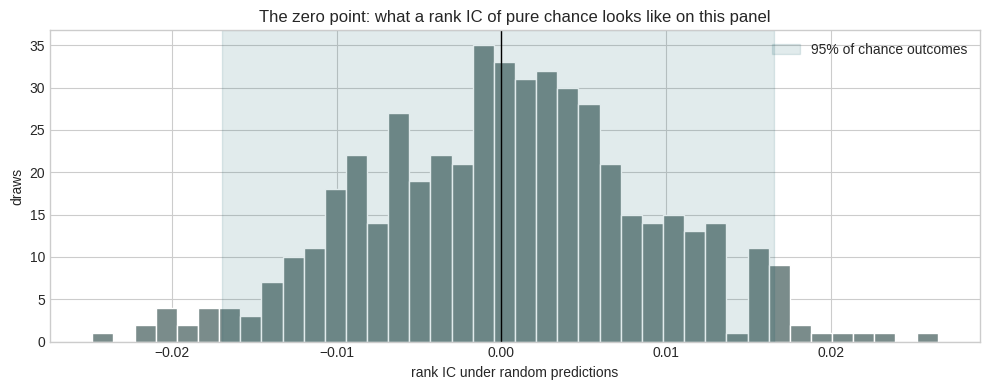

In [ ]:
# ---- empirical null distribution of rank IC --------------------------------
def random_ic_null(y_true, dates, n_draws=500, seed=0):
    rng = np.random.default_rng(seed)
    y, d = np.asarray(y_true,float), np.asarray(dates)
    groups = pd.Series(np.arange(len(y))).groupby(pd.Series(d)).groups
    draws = np.empty(n_draws)
    for i in range(n_draws):
        pred = np.empty(len(y))
        for _, idx in groups.items():
            idx = np.asarray(idx); pred[idx] = rng.normal(0,1,len(idx))
        draws[i] = rank_ic(y, pred, d)[0]
    lo, hi = np.percentile(draws, [2.5, 97.5])
    return draws, draws.mean(), draws.std(ddof=1), (lo, hi)

draws, null_mean, null_sd, (null_lo, null_hi) = random_ic_null(y_tr, d_tr, 500, RANDOM_STATE)
print(f"Empirical null, 500 draws ({train['date'].nunique()} days x 20 names):")
print(f"  mean {null_mean:+.5f} | sd {null_sd:.5f} | 95% interval [{null_lo:+.4f}, {null_hi:+.4f}]")
print(f"\n=> anything inside [{null_lo:+.4f}, {null_hi:+.4f}] is indistinguishable from chance.")

fig, ax = plt.subplots(figsize=(10,4))
ax.hist(draws, bins=40, color="#7A8C8B", edgecolor="white")
ax.axvspan(null_lo, null_hi, color="#0D5B63", alpha=.12, label="95% of chance outcomes")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("rank IC under random predictions"); ax.set_ylabel("draws")
ax.set_title("The zero point: what a rank IC of pure chance looks like on this panel")
ax.legend(); plt.tight_layout(); plt.savefig(f"{FIGS}/null_distribution.png", dpi=140); plt.show()

In [ ]:
# ---- trivial baseline models -------------------------------------------------
class ZeroPredictor(BaseEstimator, RegressorMixin):
    def fit(self, X, y): self.c_ = float(np.mean(y)); return self
    def predict(self, X): return np.full(len(X), self.c_)

class RandomPredictor(BaseEstimator, RegressorMixin):
    def __init__(self, seed=0): self.seed = seed
    def fit(self, X, y): self.sd_ = float(np.std(y)); return self
    def predict(self, X):
        return np.random.default_rng(self.seed).normal(0, self.sd_ or 1.0, len(X))

class BestSingleFeature(BaseEstimator, RegressorMixin):
    """Strongest single feature, chosen inside the training fold, sign-corrected."""
    def __init__(self, feature_names=None): self.feature_names = feature_names
    def fit(self, X, y):
        Xdf = pd.DataFrame(X, columns=self.feature_names); y = np.asarray(y,float)
        best, best_edge, sign = None, -np.inf, 1.0
        for col in Xdf.columns:
            v = Xdf[col].to_numpy(float); okm = np.isfinite(v) & np.isfinite(y)
            if okm.sum() < 100 or np.unique(v[okm]).size < 3: continue
            r = np.sign(v[okm]) * y[okm]
            g_, l_ = r[r>0].sum(), -r[r<0].sum()
            if l_ <= 0: continue
            pf_ = g_/l_
            if abs(pf_-1.) > best_edge:
                best, best_edge, sign = col, abs(pf_-1.), (1. if pf_>1 else -1.)
        self.feature_, self.sign_, self.pf_ = best, sign, 1.+best_edge*sign
        self.scale_ = float(np.std(y)); return self
    def predict(self, X):
        v = np.nan_to_num(pd.DataFrame(X, columns=self.feature_names)[self.feature_].to_numpy(float))
        sd_ = np.std(v)
        return self.sign_ * (v/sd_ if sd_>0 else v) * self.scale_

def wrap(est):
    return TransformedTargetRegressor(regressor=est, transformer=StandardScaler())

## §13. Modelling

We run eleven, spanning five genuinely different inductive biases,
so that whichever family wins says something about the problem rather than
about only having tried one kind of model.

| Family | Models | Scaling |
|---|---|---|
| Boosted trees | LightGBM, HistGBM | no - native NaN handling |
| Bagged trees | RandomForest, ExtraTrees | no |
| Penalised linear | Ridge, ElasticNet, Lasso | **yes** |
| Latent factor | PLS | **yes** |
| Kernel / distance / neural | SVR, kNN, Keras MLP | **yes** |

`StandardScaler` and `SelectKBest` are pipeline steps that are refit inside
every fold to avoide any leakage. `f_regression` scores the linear models and
`mutual_info_regression` the non-linear ones, as specified.

**Target scaling.** Every estimator is wrapped in a `TransformedTargetRegressor`
that standardises y during fitting and inverts on predict. The target's sd
is 0.024, so unwrapped, SVR's default `epsilon=0.1` would be 4.2x the
target's entire spread - it would silently keep 59 support vectors out of
8,000 and return a near-constant while looking perfectly converged. Wrapped,
every regularisation constant is in standard deviations.

**Neural network**: *loss* - Huber (raw kurtosis is 36.5, so squared error would spend the gradient on a handful of earnings gaps); *penalties* - L2 on every dense layer, plus dropout and early stopping; *sample weights* - proportional to |y|, since the strategy only
ever trades the extreme quantiles. Early stopping holds out a seeded random
15% of the training rows - the code comment explains why Keras' raw
`validation_split` was wrong for ticker-major data - and never touches the
CV validation fold.

In [ ]:
def mi_score(X, y): return mutual_info_regression(X, y, random_state=RANDOM_STATE)
def IMPUTE(): return ("impute", SimpleImputer(strategy="median"))
def SCALE():  return ("scale",  StandardScaler())

class KerasMLP(BaseEstimator, RegressorMixin):
    def __init__(self, hidden=(64,32), dropout=0.3, l2=1e-3, lr=1e-3, epochs=200,
                 batch_size=256, huber_delta=1.0, sample_weighting=True,
                 patience=12, seed=RANDOM_STATE):
        self.hidden=hidden; self.dropout=dropout; self.l2=l2; self.lr=lr
        self.epochs=epochs; self.batch_size=batch_size; self.huber_delta=huber_delta
        self.sample_weighting=sample_weighting; self.patience=patience; self.seed=seed
    def fit(self, X, y):
        import keras
        from keras import layers, regularizers
        keras.utils.set_random_seed(self.seed)
        X = np.asarray(X,dtype="float32"); y = np.asarray(y,dtype="float32").ravel()

        # Rows arrive TICKER-MAJOR (every date of one ticker, then the next), and
        # Keras' validation_split carves the LAST fraction of rows BEFORE any
        # shuffling. Early stopping was therefore always scored on the same ~3
        # alphabetical tickers (WRBY/WSBC/XPO) across ALL dates -- not the
        # "chronological tail" an earlier comment claimed -- and shuffle=False
        # made every batch a single ticker's contiguous block. Permuting with a
        # seed makes the 15% early-stopping slice an unbiased sample of names and
        # dates; every row is still a training-fold row, so nothing leaks.
        rng = np.random.default_rng(self.seed)
        perm = rng.permutation(len(X))
        X, y = X[perm], y[perm]

        net = keras.Sequential([keras.Input(shape=(X.shape[1],))])
        for h in self.hidden:
            net.add(layers.Dense(h, activation="relu",
                                 kernel_regularizer=regularizers.l2(self.l2)))
            net.add(layers.Dropout(self.dropout))
        net.add(layers.Dense(1))
        net.compile(optimizer=keras.optimizers.Adam(self.lr),
                    loss=keras.losses.Huber(delta=self.huber_delta))
        w = None
        if self.sample_weighting:
            w = np.abs(y); w = w/w.mean() if w.mean()>0 else np.ones_like(y)
        net.fit(X, y, sample_weight=w, epochs=self.epochs, batch_size=self.batch_size,
                verbose=0, shuffle=True, validation_split=0.15,
                callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",
                           patience=self.patience, restore_best_weights=True)])
        self.model_ = net; return self
    def predict(self, X):
        return self.model_.predict(np.asarray(X,dtype="float32"), verbose=0).ravel()

K = len(FEATURES)
MODELS = {
 "LightGBM": {"factory": lambda: wrap(LGBMRegressor(random_state=RANDOM_STATE, verbose=-1,
        n_estimators=400, colsample_bytree=0.7, subsample=0.8, subsample_freq=1)),
    "grid": [{"num_leaves":nl,"learning_rate":lr,"min_child_samples":mcs,"reg_lambda":rl}
             for nl in (7,15) for lr in (0.02,0.05) for mcs in (100,300) for rl in (5.,20.)],
    "family":"boosted trees","scaled":False},
 "HistGBM": {"factory": lambda: wrap(HistGradientBoostingRegressor(
        random_state=RANDOM_STATE, max_iter=400, early_stopping=False)),
    "grid": [{"max_leaf_nodes":ml,"learning_rate":lr,"min_samples_leaf":msl,"l2_regularization":l2}
             for ml in (7,15) for lr in (0.02,0.05) for msl in (100,300) for l2 in (1.,10.)],
    "family":"boosted trees","scaled":False},
 "RandomForest": {"factory": lambda: wrap(Pipeline([IMPUTE(),
        ("model", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))])),
    "grid": [{"model__max_depth":d,"model__min_samples_leaf":lf,"model__max_features":mf}
             for d in (4,8) for lf in (50,200) for mf in (0.3,0.6)],
    "family":"bagged trees","scaled":False},
 "ExtraTrees": {"factory": lambda: wrap(Pipeline([IMPUTE(),
        ("model", ExtraTreesRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))])),
    "grid": [{"model__max_depth":d,"model__min_samples_leaf":lf,"model__max_features":mf}
             for d in (4,8) for lf in (50,200) for mf in (0.3,0.6)],
    "family":"bagged trees","scaled":False},
 "Ridge": {"factory": lambda: wrap(Pipeline([IMPUTE(), SCALE(),
        ("select", SelectKBest(score_func=f_regression)), ("model", Ridge(random_state=RANDOM_STATE))])),
    "grid": [{"select__k":k,"model__alpha":a} for k in (15,K) for a in (1.,10.,100.,1000.)],
    "family":"penalised linear","scaled":True},
 "ElasticNet": {"factory": lambda: wrap(Pipeline([IMPUTE(), SCALE(),
        ("select", SelectKBest(score_func=f_regression)),
        ("model", ElasticNet(max_iter=5000, random_state=RANDOM_STATE))])),
    "grid": [{"select__k":k,"model__alpha":a,"model__l1_ratio":l1}
             for k in (15,K) for a in (1e-4,1e-3,1e-2) for l1 in (0.15,0.9)],
    "family":"penalised linear","scaled":True},
 "Lasso": {"factory": lambda: wrap(Pipeline([IMPUTE(), SCALE(),
        ("select", SelectKBest(score_func=f_regression)),
        ("model", Lasso(max_iter=5000, random_state=RANDOM_STATE))])),
    "grid": [{"select__k":k,"model__alpha":a} for k in (15,K) for a in (1e-5,1e-4,1e-3)],
    "family":"penalised linear","scaled":True},
 "PLS": {"factory": lambda: wrap(Pipeline([IMPUTE(), SCALE(),
        ("model", PLSRegression())])),
    "grid": [{"model__n_components":n} for n in (1,2,3,5,8)],
    "family":"latent factor","scaled":True},
 "SVR": {"factory": lambda: wrap(Pipeline([IMPUTE(), SCALE(),
        ("select", SelectKBest(score_func=mi_score)), ("model", SVR(kernel="rbf", cache_size=1000))])),
    "grid": [{"select__k":k,"model__C":c,"model__epsilon":e,"model__gamma":"scale"}
             for k in (15,) for c in (0.1,0.3,1.0) for e in (0.02,0.05,0.2)],
    "family":"kernel","scaled":True},
 "kNN": {"factory": lambda: wrap(Pipeline([IMPUTE(), SCALE(),
        ("select", SelectKBest(score_func=mi_score)), ("model", KNeighborsRegressor(n_jobs=-1))])),
    "grid": [{"select__k":k,"model__n_neighbors":nn,"model__weights":w}
             for k in (10,15) for nn in (100,300,800) for w in ("uniform","distance")],
    "family":"distance","scaled":True},
 "KerasMLP": {"factory": lambda: wrap(Pipeline([IMPUTE(), SCALE(),
        ("select", SelectKBest(score_func=mi_score)), ("model", KerasMLP())])),
    "grid": [{"select__k":k,"model__hidden":h,"model__dropout":dr,"model__l2":l2}
             for k in (15,K) for h in ((32,),(64,32)) for dr in (0.3,) for l2 in (1e-3,1e-2)],
    "family":"neural","scaled":True},
}
BASELINES = {
 "ZeroPredictor":    {"factory": lambda: wrap(ZeroPredictor()), "grid":[{}],
                      "family":"baseline","scaled":False},
 "RandomPredictor":  {"factory": lambda: wrap(RandomPredictor(seed=RANDOM_STATE)), "grid":[{}],
                      "family":"baseline","scaled":False},
 "BestSingleFeature":{"factory": lambda: wrap(BestSingleFeature(feature_names=FEATURES)),
                      "grid":[{}], "family":"baseline","scaled":False},
}
print(f"{'model':16s} {'family':18s} {'configs':>8s} {'scaled':>7s}")
for n,s in {**BASELINES, **MODELS}.items():
    print(f"{n:16s} {s['family']:18s} {len(s['grid']):8d} {str(s['scaled']):>7s}")
print(f"\n{sum(len(s['grid']) for s in MODELS.values())*5} fits for the grid search.")

model            family              configs  scaled
ZeroPredictor    baseline                  1   False
RandomPredictor  baseline                  1   False
BestSingleFeature baseline                  1   False
LightGBM         boosted trees            16   False
HistGBM          boosted trees            16   False
RandomForest     bagged trees              8   False
ExtraTrees       bagged trees              8   False
Ridge            penalised linear          8    True
ElasticNet       penalised linear         12    True
Lasso            penalised linear          6    True
PLS              latent factor             5    True
SVR              kernel                    9    True
kNN              distance                 12    True
KerasMLP         neural                    8    True

540 fits for the grid search.


## §14. Manual grid-search cross-validation loop

Manual grid search is the only one that returns **out-of-fold predictions** — a single number from `cross_val_score` cannot produce a directional-accuracy-by-quantile table, nor be turned into an equity curve later.

**Scoring is per fold, then averaged — not pooled.** A model that is excellent in
one fold and useless in four is not a good model, and pooling conceals that
entirely. The reported standard error is across folds.

In [ ]:
# ---- cross-validated out-of-fold predictions ---------------------------------
def build(spec, params):
    est = clone(spec["factory"]())
    if params: est.set_params(**{f"regressor__{k}": v for k,v in params.items()})
    return est

def _fold_fit_target(y_raw, tr, winsor_sd=WINSOR_SD):
    """Winsorise using ONLY the training fold's own scale.

    Clipping once on the whole training block would set the threshold using
    validation-fold data. Small, but it is a leak, and it costs nothing to close.
    """
    sd_ = y_raw[tr].std()
    return np.clip(y_raw[tr], -winsor_sd*sd_, winsor_sd*sd_)

def cv_oof(spec, params, X, y_raw, dates, cv):
    total, count = np.zeros(len(y_raw)), np.zeros(len(y_raw))
    for tr, va in cv.split(X, y_raw, groups=dates):
        est = build(spec, params); est.fit(X.iloc[tr], _fold_fit_target(y_raw, tr))
        total[va] += est.predict(X.iloc[va]); count[va] += 1
    return np.where(count>0, total/np.maximum(count,1), np.nan)

def fold_scores(spec, params, X, y_raw, dates, cv):
    out = []
    for tr, va in cv.split(X, y_raw, groups=dates):
        est = build(spec, params); est.fit(X.iloc[tr], _fold_fit_target(y_raw, tr))
        ic,_,_,_ = rank_ic(y_raw[va], est.predict(X.iloc[va]), dates[va])
        out.append(ic if np.isfinite(ic) else 0.0)
    return np.asarray(out)

def run_roster(roster, X, y_raw, dates, cv):
    results = {}
    for name, spec in roster.items():
        t0, best = time.time(), None
        for params in spec["grid"]:
            ics = fold_scores(spec, params, X, y_raw, dates, cv)
            # A non-finite incumbent must be displaced explicitly: (x > nan) is
            # always False, so a NaN first configuration would otherwise stick as
            # "best" for the entire remaining grid.
            if (best is None or not np.isfinite(best["mean_fold_ic"])
                    or (np.isfinite(ics.mean()) and ics.mean() > best["mean_fold_ic"])):
                best = {"params":params, "mean_fold_ic":float(ics.mean()),
                        "fold_ic_se":float(ics.std(ddof=1)/np.sqrt(len(ics))), "fold_ics":ics}
        best["oof"] = cv_oof(spec, best["params"], X, y_raw, dates, cv)
        m = np.isfinite(best["oof"])
        rep = report(y_raw[m], best["oof"][m], dates[m], label=name, verbose=False)
        results[name] = {**best, **rep, "family":spec["family"]}
        print(f"  {name:16s} meanFoldIC {best['mean_fold_ic']:+.4f} "
              f"(se {best['fold_ic_se']:.4f})  positive in "
              f"{int((best['fold_ics']>0).sum())}/{len(best['fold_ics'])} folds  "
              f"[{time.time()-t0:.0f}s]")
    return results

print("Baselines:");  base_results = run_roster(BASELINES, X_tr, y_tr, d_tr, CV)
bsf = build(BASELINES["BestSingleFeature"], {}); bsf.fit(X_tr, y_tr_w)
print(f"\n  BestSingleFeature picked: {bsf.regressor_.feature_} "
      f"(train PF {bsf.regressor_.pf_:.4f}, sign {'+' if bsf.regressor_.sign_>0 else '-'})")
print("\nModels:"); t0 = time.time()
results = run_roster(MODELS, X_tr, y_tr, d_tr, CV)
print(f"\ncompleted in {(time.time()-t0)/60:.1f} min")

Baselines:
  ZeroPredictor    meanFoldIC +0.0000 (se 0.0000)  positive in 0/5 folds  [0s]
  RandomPredictor  meanFoldIC +0.0025 (se 0.0082)  positive in 3/5 folds  [3s]
  BestSingleFeature meanFoldIC +0.0144 (se 0.0133)  positive in 3/5 folds  [2s]

  BestSingleFeature picked: z_iv_skew (train PF 0.9154, sign -)

Models:
  LightGBM         meanFoldIC +0.0302 (se 0.0070)  positive in 5/5 folds  [88s]
  HistGBM          meanFoldIC +0.0344 (se 0.0121)  positive in 5/5 folds  [122s]
  RandomForest     meanFoldIC +0.0261 (se 0.0165)  positive in 4/5 folds  [531s]
  ExtraTrees       meanFoldIC +0.0243 (se 0.0130)  positive in 4/5 folds  [72s]
  Ridge            meanFoldIC +0.0221 (se 0.0176)  positive in 3/5 folds  [8s]
  ElasticNet       meanFoldIC +0.0208 (se 0.0167)  positive in 3/5 folds  [13s]
  Lasso            meanFoldIC +0.0206 (se 0.0152)  positive in 3/5 folds  [8s]
  PLS              meanFoldIC +0.0245 (se 0.0151)  positive in 4/5 folds  [5s]
  SVR              meanFoldIC +0.0220 

## §15. Selection and fine-tuning - the one-standard-error rule

Six of the eleven models land within one standard error of the best mean
fold IC, a band narrower than their own standard errors, so they are not
really six distinguishable models. Taking the maximum of several correlated
noisy estimates is upward-biased even when every model is equally good, and
that bias is paid back on the test set. The rule is therefore: take the best
mean fold IC, then among everything within one standard error of it, take
the simplest model.

The fine-tune grid always includes the stage-1 incumbent. Without it, a
refined search over a neighbourhood that happens to exclude the incumbent
can only move sideways or down - and in an earlier run it did exactly that,
costing 0.0073 of mean fold IC while keeping the worse configuration.

In [ ]:
#---- select the simplest model within one standard error of the best ---------------

# define a complexity ordering of the model families, so that we can pick the simplest
COMPLEXITY = {"baseline":0,"penalised linear":1,"latent factor":2,"distance":3,
              "bagged trees":4,"kernel":5,"boosted trees":6,"neural":7}
all_results = {**base_results, **results}
tab = pd.DataFrame([{"model":n, "family":r["family"], "mean_fold_ic":r["mean_fold_ic"],
                     "fold_ic_se":r["fold_ic_se"],
                     "folds_positive":int((r["fold_ics"]>0).sum()),
                     "oof_RankIC":r["RankIC"], "oof_RankIC_t":r["RankIC_t"],
                     "MAE":r["MAE"], "ProfitFactor":r["ProfitFactor"],
                     "DirAcc":r["DirAcc"], "Skill":r["Skill"], "DegenDays":r["DegenDays"],
                     "complexity":COMPLEXITY[r["family"]]}
                    for n,r in all_results.items()]).sort_values(
                        "mean_fold_ic", ascending=False).reset_index(drop=True)

#threshold for "within one standard error" of the best model's mean fold IC
thr = tab.iloc[0]["mean_fold_ic"] - tab.iloc[0]["fold_ic_se"]
tab["within_1se"] = tab["mean_fold_ic"] >= thr
singles = tab[(tab["within_1se"]) & (tab["family"]!="baseline")].sort_values(
    ["complexity","mean_fold_ic"], ascending=[True,False])
WINNER = singles.iloc[0]["model"]
tab["selected"] = tab["model"] == WINNER

print("Ranked by MEAN FOLD rank IC (not pooled):\n")
print(tab.drop(columns="complexity").to_string(index=False, float_format=lambda x:f"{x:.4f}"))
print(f"\nBest mean fold IC : {tab.iloc[0]['model']} at {tab.iloc[0]['mean_fold_ic']:+.4f} "
      f"(se {tab.iloc[0]['fold_ic_se']:.4f})")
print(f"Within 1 s.e.     : {', '.join(tab[tab['within_1se']]['model'])}")
print(f"SELECTED          : {WINNER}  (simplest family within one standard error)")
bsf_ic = tab.loc[tab.model=='BestSingleFeature','mean_fold_ic'].iloc[0]
win_ic = tab.loc[tab.model==WINNER,'mean_fold_ic'].iloc[0]
print(f"\nvs single-feature baseline : {win_ic:+.4f} against {bsf_ic:+.4f} ({win_ic-bsf_ic:+.4f})")
print(f"vs chance (null 95% upper {null_hi:+.4f}) : "
      f"{'clears it' if win_ic>null_hi else 'INSIDE the null'}")
print(f"  the single-feature baseline is {'INSIDE' if bsf_ic<=null_hi else 'outside'} the null "
      "-- one feature alone is not distinguishable from chance")
tab.to_csv("results_model_comparison.csv", index=False)

Ranked by MEAN FOLD rank IC (not pooled):

            model           family  mean_fold_ic  fold_ic_se  folds_positive  oof_RankIC  oof_RankIC_t    MAE  ProfitFactor  DirAcc   Skill  DegenDays  within_1se  selected
          HistGBM    boosted trees        0.0344      0.0121               5      0.0344        3.1139 0.0158        1.0594 50.5909 -0.0273          0        True     False
         LightGBM    boosted trees        0.0302      0.0070               5      0.0302        2.5781 0.0153        1.0638 51.0727  0.4545          0        True     False
         KerasMLP           neural        0.0300      0.0095               5      0.0300        2.5074 0.0157        1.0584 51.2364  0.6182          0        True     False
     RandomForest     bagged trees        0.0261      0.0165               4      0.0261        2.1945 0.0148        1.0440 50.5727 -0.0455          0        True     False
              PLS    latent factor        0.0245      0.0151               4      0.0245    

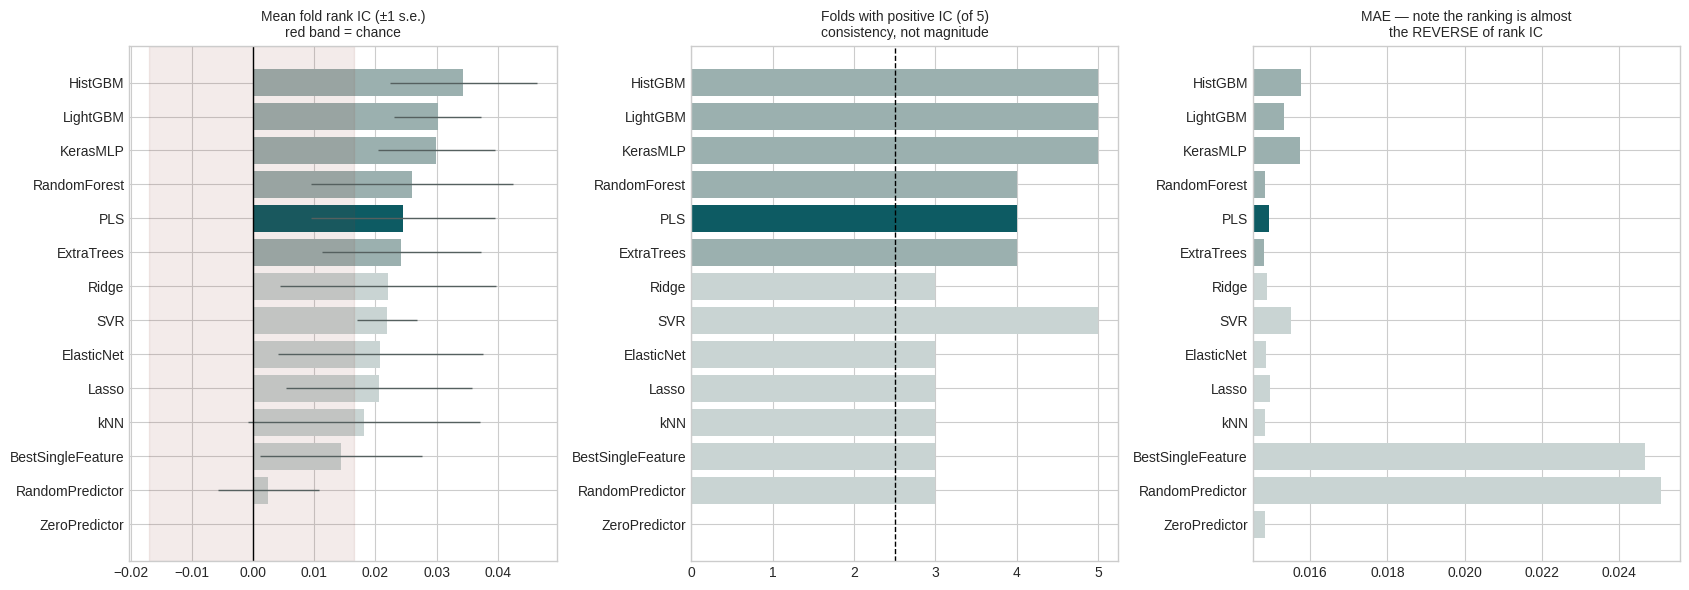

In [ ]:
# visualise the results
fig, axes = plt.subplots(1,3, figsize=(17,6))
t = tab.iloc[::-1]
cols = ["#0D5B63" if s else ("#9BB0AF" if w else "#C9D4D3")
        for s,w in zip(t["selected"], t["within_1se"])]
axes[0].barh(t["model"], t["mean_fold_ic"], color=cols, xerr=t["fold_ic_se"],
             error_kw=dict(ecolor="#55605F", lw=1))
axes[0].axvspan(null_lo, null_hi, color="#8B3F33", alpha=.10)
axes[0].axvline(0, color="black", lw=1)
axes[0].set_title("Mean fold rank IC (±1 s.e.)\nred band = chance", fontsize=10)
axes[1].barh(t["model"], t["folds_positive"], color=cols)
axes[1].axvline(2.5, color="black", ls="--", lw=1)
axes[1].set_title("Folds with positive IC (of 5)\nconsistency, not magnitude", fontsize=10)
axes[2].barh(t["model"], t["MAE"], color=cols)
axes[2].set_xlim(t["MAE"].min()*.98, t["MAE"].max()*1.02)
axes[2].set_title("MAE — note the ranking is almost\nthe REVERSE of rank IC", fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIGS}/model_comparison.png", dpi=140); plt.show()

In [ ]:
# fine-tune the selected model's hyperparameters ---------------------------------
spec = MODELS[WINNER]; base_params = all_results[WINNER]["params"]
FINE = {
 "LightGBM":     [dict(base_params, num_leaves=nl, learning_rate=lr, reg_lambda=rl)
                  for nl in (5,7,11) for lr in (0.01,0.02) for rl in (10.,30.)],
 "HistGBM":      [dict(base_params, max_leaf_nodes=ml, learning_rate=lr, l2_regularization=l2)
                  for ml in (5,7,11) for lr in (0.01,0.02) for l2 in (5.,20.)],
 "RandomForest": [dict(base_params, **{"model__max_depth":d,"model__min_samples_leaf":lf})
                  for d in (3,4,6) for lf in (100,200,400)],
 "ExtraTrees":   [dict(base_params, **{"model__max_depth":d,"model__min_samples_leaf":lf})
                  for d in (3,4,6) for lf in (100,200,400)],
 "Ridge":        [dict(base_params, **{"model__alpha":a}) for a in (10.,30.,100.,300.,1000.,3000.)],
 "ElasticNet":   [dict(base_params, **{"model__alpha":a,"model__l1_ratio":l1})
                  for a in (3e-4,1e-3,3e-3,1e-2) for l1 in (0.1,0.5,0.9)],
 "SVR":          [dict(base_params, **{"model__C":c,"model__epsilon":e})
                  for c in (0.05,0.1,0.3) for e in (0.02,0.05,0.1)],
 "Lasso":        [dict(base_params, **{"model__alpha":a})
                  for a in (3e-6,1e-5,3e-5,1e-4,3e-4)],
 "PLS":          [dict(base_params, **{"model__n_components":n}) for n in (1,2,3,4,6,10)],
 "kNN":          [dict(base_params, **{"model__n_neighbors":nn}) for nn in (200,400,600,800,1200)],
 "KerasMLP":     [dict(base_params, **{"model__dropout":dr,"model__l2":l2})
                  for dr in (0.2,0.3,0.4) for l2 in (1e-3,1e-2)],
}[WINNER]
FINE = [base_params] + [f for f in FINE if f != base_params]   # incumbent always included

best_fine, t0 = None, time.time()
for params in FINE:
    ics = fold_scores(spec, params, X_tr, y_tr, d_tr, CV)
    if best_fine is None or ics.mean() > best_fine["ic"]:
        best_fine = {"params":params, "ic":float(ics.mean()),
                     "se":float(ics.std(ddof=1)/np.sqrt(len(ics))), "ics":ics}
stage1 = all_results[WINNER]["mean_fold_ic"]
print(f"Fine-tuning {WINNER}: {len(FINE)} configurations (incumbent included) in {time.time()-t0:.0f}s")
print(f"  stage-1 incumbent {stage1:+.4f} -> "
      f"{'improved' if best_fine['ic']>stage1 else 'not beaten (incumbent kept)'}")
print(f"  best mean fold IC {best_fine['ic']:+.4f} (se {best_fine['se']:.4f}), "
      f"positive in {int((best_fine['ics']>0).sum())}/5 folds")
print(f"  params: {best_fine['params']}")
FINAL_PARAMS = best_fine["params"]
oof_final = cv_oof(spec, FINAL_PARAMS, X_tr, y_tr, d_tr, CV)

Fine-tuning PLS: 7 configurations (incumbent included) in 8s
  stage-1 incumbent +0.0245 -> not beaten (incumbent kept)
  best mean fold IC +0.0245 (se 0.0151), positive in 4/5 folds
  params: {'model__n_components': 5}


## §16. Held-out test evaluation

Refit on the whole training block with the tuned parameters, predict once.
Nothing below has influenced any choice above — the test set has been untouched
since §8.

In [ ]:
final = build(spec, FINAL_PARAMS); final.fit(X_tr, y_tr_w)
pred_te = final.predict(X_te)
varies = pd.Series(pred_te).groupby(pd.Series(d_te)).nunique().gt(1)
print(f"Test days on which the prediction varies across the 20 names: {varies.sum()} of {len(varies)}")
assert varies.mean() > 0.5, "the fitted model gives no cross-sectional ordering"

m = np.isfinite(oof_final)
res_val = report(y_tr[m], oof_final[m], d_tr[m], label=f"{WINNER} — VALIDATION (out-of-fold)")
res_te  = report(y_te, pred_te, d_te,       label=f"{WINNER} — TEST (held out)")

side = pd.DataFrame([
 {"metric":"Mean absolute error","validation":res_val["MAE"],"test":res_te["MAE"]},
 {"metric":"Profit Factor","validation":res_val["ProfitFactor"],"test":res_te["ProfitFactor"]},
 {"metric":"Spearman rank IC","validation":res_val["RankIC"],"test":res_te["RankIC"]},
 {"metric":"Rank IC t-stat","validation":res_val["RankIC_t"],"test":res_te["RankIC_t"]},
 {"metric":"Directional accuracy %","validation":res_val["DirAcc"],"test":res_te["DirAcc"]},
 {"metric":"Naive baseline %","validation":res_val["NaiveDirAcc"],"test":res_te["NaiveDirAcc"]},
 {"metric":"Skill (pct points)","validation":res_val["Skill"],"test":res_te["Skill"]}])
print("\n\nVALIDATION vs TEST\n"); print(side.to_string(index=False, float_format=lambda x:f"{x:+.4f}"))
print(f"\nRank IC degradation: {res_val['RankIC']-res_te['RankIC']:+.4f}")

# Every model on the test set -- a DIAGNOSTIC run after selection was locked and
# fed back into nothing. It answers one question: was the outcome specific to the
# selected model, or did none of them carry?
diag, test_preds = [], []
for name, sp in MODELS.items():
    est = build(sp, all_results[name]["params"]); est.fit(X_tr, y_tr_w)
    p = est.predict(X_te)
    ic,t_,nd,_ = rank_ic(y_te, p, d_te)
    diag.append({"model":name,"val_mean_fold_ic":all_results[name]["mean_fold_ic"],
                 "test_RankIC":ic,"test_t":t_,"test_PF":signal_profit_factor(y_te,p)})
    test_preds.append(test[["date","ticker","target","fwd_logret"]].assign(model=name, pred=p))
diag = pd.DataFrame(diag).sort_values("val_mean_fold_ic", ascending=False)
allm = pd.concat(test_preds, ignore_index=True)
print("\n\nPOST-HOC DIAGNOSTIC — every model on the test set (not used for selection):\n")
print(diag.to_string(index=False, float_format=lambda x:f"{x:+.4f}"))
print(f"\nmean test rank IC across {len(diag)} models: {diag['test_RankIC'].mean():+.4f}")
print(f"models positive out of sample: {int((diag['test_RankIC']>0).sum())} of {len(diag)}")
diag.to_csv("results_test_diagnostic.csv", index=False)

Test days on which the prediction varies across the 20 names: 248 of 248

PLS — VALIDATION (out-of-fold)
  Mean absolute error : 0.014946
  Profit Factor       : 1.0488
  Spearman Rank IC    : +0.0245  (t = +2.01 over 550 days)
  Naive hit rate      : 50.62%   Model hit rate: 50.65%
  Skill vs naive      : +0.03 pct points

  Directional accuracy by absolute-move quintile:
            Hit Rate     N  % of Total    Naive    Skill  Mean |move|
q                                                                    
Q1 (tiny)     0.5114  2200     20.0000   0.5109   0.0005       0.0019
Q2            0.5014  2200     20.0000   0.5114  -0.0100       0.0058
Q3            0.5068  2200     20.0000   0.5105  -0.0036       0.0105
Q4            0.5027  2200     20.0000   0.5105  -0.0077       0.0171
Q5 (large)    0.5100  2200     20.0000   0.5123  -0.0023       0.0388

PLS — TEST (held out)
  Mean absolute error : 0.014576
  Profit Factor       : 0.9849
  Spearman Rank IC    : +0.0052  (t = +0.33 ove

## S17. Did the edge decay, or was it never there?

Ten of the eleven models went negative on the test set. The one exception is
PLS, this run's selected model, at +0.005 with t = +0.33 - inside the chance
band from §12. Two explanations fit that, with different implications:

- **Overfitting** - the validation edge was never real, and the test set
  just revealed it. Out-of-fold IC would hover near zero throughout.
- **Alpha decay** - the relationships held in the training window and then
  stopped holding. IC would start positive and fade, including inside the
  training window, where nothing was overfit.

A rolling rank IC over the whole sample separates the two cases.

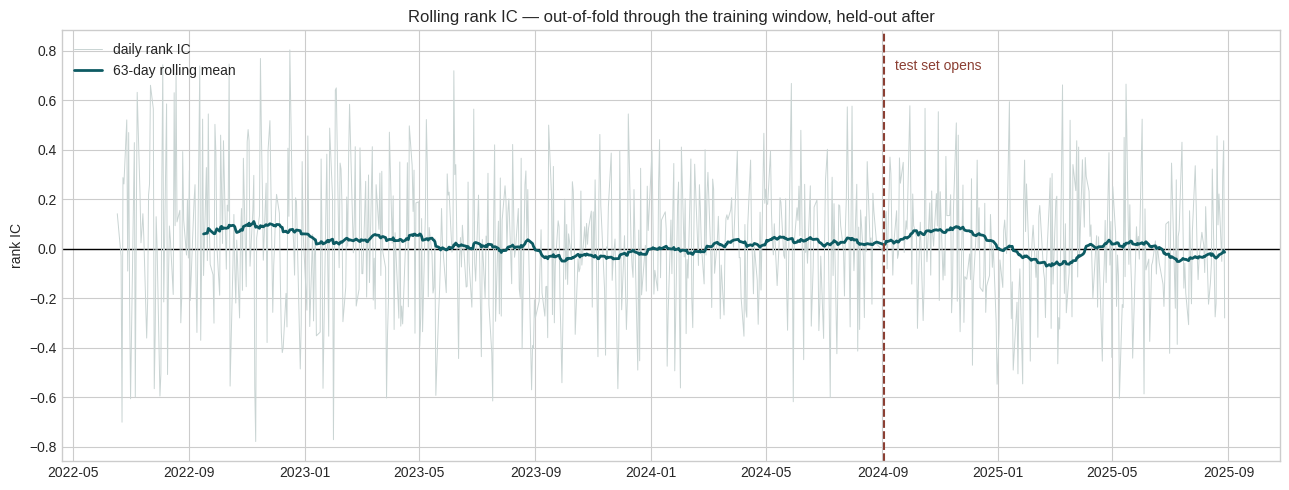

Mean daily rank IC by calendar year:

        mean    std  count
2022  0.0654 0.3456    136
2023  0.0005 0.2742    250
2024  0.0307 0.2380    248
2025 -0.0113 0.2528    164

out-of-fold (train window): +0.0245 over 550 days
held-out test             : +0.0052 over 248 days

The decline is visible INSIDE the training window, where nothing was
overfit to. That points at alpha decay rather than overfitting.


In [ ]:
ic_tr  = daily_ic_series(y_tr[m], oof_final[m], d_tr[m])
ic_te  = daily_ic_series(y_te, pred_te, d_te)
ic_all = pd.concat([ic_tr, ic_te]).sort_index()
W = 63
roll = ic_all.rolling(W).mean()

fig, ax = plt.subplots(figsize=(13,5))
ax.axhline(0, color="black", lw=1)
ax.plot(ic_all.index, ic_all.values, color="#C9D4D3", lw=.7, label="daily rank IC")
ax.plot(roll.index, roll.values, color="#0D5B63", lw=2, label=f"{W}-day rolling mean")
ax.axvline(test["date"].min(), color="#8B3F33", ls="--", lw=1.5)
ax.annotate("test set opens", xy=(test["date"].min(), ax.get_ylim()[1]*.82),
            xytext=(8,0), textcoords="offset points", color="#8B3F33", fontsize=10)
ax.set_ylabel("rank IC"); ax.legend(loc="upper left")
ax.set_title("Rolling rank IC — out-of-fold through the training window, held-out after")
plt.tight_layout(); plt.savefig(f"{FIGS}/rolling_ic.png", dpi=140); plt.show()

by_year = ic_all.groupby(ic_all.index.year).agg(["mean","std","count"])
print("Mean daily rank IC by calendar year:\n")
print(by_year.to_string(float_format=lambda x:f"{x:.4f}"))
print(f"\nout-of-fold (train window): {ic_tr.mean():+.4f} over {len(ic_tr)} days")
print(f"held-out test             : {ic_te.mean():+.4f} over {len(ic_te)} days")
print("\nThe decline is visible INSIDE the training window, where nothing was")
print("overfit to. That points at alpha decay rather than overfitting.")

## §18. SHAP — feature importance on the test set

A model-agnostic `PermutationExplainer` is used rather than `TreeExplainer`,
because the estimator is a `TransformedTargetRegressor` wrapping a pipeline —
explaining predict end-to-end attributes importance in the units the strategy
actually consumes, and keeps this correct whichever family won.

SHAP over 300 test rows in 14s

Top 15 by mean |SHAP| on the test set:

       feature  mean_abs_shap             bucket
         z_dtc       0.000570 exogenous/calendar
z_stock_spread       0.000513 exogenous/calendar
     z_iv_skew       0.000455 exogenous/calendar
       z_mom_5       0.000395                bar
      z_iv_30d       0.000385 exogenous/calendar
         z_ppo       0.000373                bar
      z_cmf_20       0.000323                bar
       z_iv_rv       0.000309 exogenous/calendar
 z_beta_umd_60       0.000303 exogenous/calendar
       z_atr_c       0.000299                bar
      z_roc_10       0.000284                bar
     z_cmma_20       0.000253                bar
     z_beta_60       0.000234 exogenous/calendar
 z_sect_rel_21       0.000231 exogenous/calendar
    z_gex_norm       0.000218 exogenous/calendar

Share of total importance: bar 38%  exogenous/calendar 62%


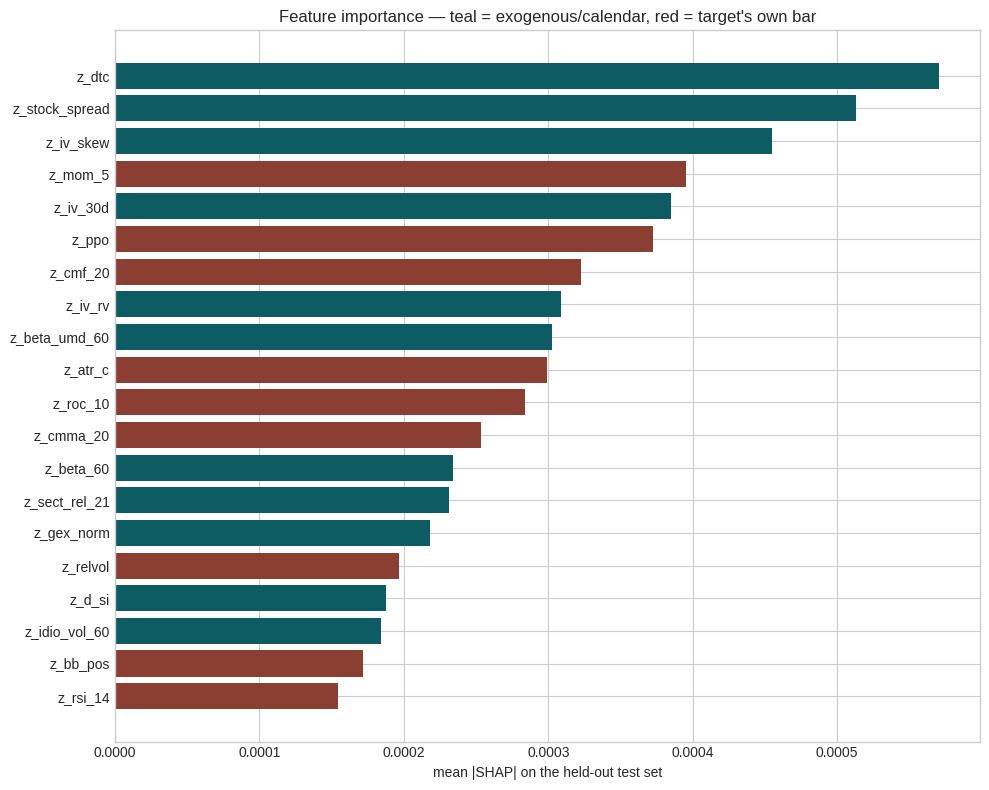

In [ ]:
import shap
rng = np.random.default_rng(RANDOM_STATE)
bg = X_tr.iloc[rng.choice(len(X_tr), 100, replace=False)].fillna(X_tr.median())
ex = X_te.iloc[rng.choice(len(X_te), 300, replace=False)].fillna(X_tr.median())
t0 = time.time()
sv = shap.PermutationExplainer(final.predict, bg)(ex, max_evals=2*len(FEATURES)+1, silent=True)
print(f"SHAP over {len(ex)} test rows in {time.time()-t0:.0f}s")

imp = pd.DataFrame({"feature":FEATURES,"mean_abs_shap":np.abs(sv.values).mean(axis=0)}) \
        .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
imp["bucket"] = ["bar" if f.replace("z_","") in BAR else "exogenous/calendar" for f in imp["feature"]]
share = imp.groupby("bucket")["mean_abs_shap"].sum()
print("\nTop 15 by mean |SHAP| on the test set:\n")
print(imp.head(15).to_string(index=False, float_format=lambda x:f"{x:.6f}"))
print(f"\nShare of total importance: " + "  ".join(f"{k} {v/share.sum():.0%}" for k,v in share.items()))
imp.to_csv("results_shap_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(10,8))
top = imp.head(20).iloc[::-1]
ax.barh(top["feature"], top["mean_abs_shap"],
        color=["#8B3F33" if b=="bar" else "#0D5B63" for b in top["bucket"]])
ax.set_xlabel("mean |SHAP| on the held-out test set")
ax.set_title("Feature importance — teal = exogenous/calendar, red = target's own bar")
plt.tight_layout(); plt.savefig(f"{FIGS}/shap_importance.png", dpi=140); plt.show()

## §19. Trading strategy

> **Every day, rank all 20 stocks by the model's predicted next-day
> market-relative return. Buy the 4 with the highest predictions. Short the 4
> with the lowest. Put an equal amount of money in each of the 8 positions, so
> the longs and the shorts cancel out and the book is dollar-neutral. Repeat
> tomorrow.**


Costs are charged three ways so the result cannot rest on an optimistic
assumption: the stock's **actual quoted half-spread** on each traded name, and
flat **5 bps** and **10 bps** round-trip alternatives. Turnover is tracked
explicitly.

Because positions are $1/8$ each, the strategy's gross daily return is exactly
half the Q5−Q1 spread.

In [ ]:
N_POS = 8                                            # 4 long + 4 short
FLAT_BPS = {"5bpsRT": 2.5e-4, "10bpsRT": 5.0e-4}     # per side; RT = round trip

def backtest(df):
    """Equal-weight quintile long-short, daily rebalance.

    Weights: +1/8 on the 4 highest-prediction names, -1/8 on the 4 lowest, so the
    book sums to zero with unit gross. Daily P&L is sum(w * target); using the
    demeaned target equals using fwd_logret because the demeaning constant
    cancels between the long and short legs.
    """
    rows, prev_w = [], None
    for _, g in df.groupby("date"):
        g = g.sort_values("pred", kind="mergesort")
        k = len(g)//5
        w = pd.Series(0.0, index=g.index)
        w.iloc[:k] = -1.0/N_POS
        w.iloc[len(g)-k:] = 1.0/N_POS
        gross = float((w * g["target"]).sum())
        spread = g["spread_raw"].fillna(g["spread_raw"].median()).fillna(0.0).to_numpy()
        dw = w.abs().to_numpy() if prev_w is None else \
             (w - prev_w.reindex(w.index).fillna(0.0)).abs().to_numpy()
        rows.append({"date": g["date"].iloc[0], "gross": gross,
                     "net_spread": gross - float(np.sum(dw*spread/2.0)),
                     **{f"net_{n}": gross - float(dw.sum())*h for n,h in FLAT_BPS.items()},
                     "turnover": dw.sum()/2.0, "cost_spread": float(np.sum(dw*spread/2.0))})
        prev_w = w
    return pd.DataFrame(rows).set_index("date")

te_df = test[["date","ticker","target","fwd_logret","spread_raw"]].copy()
te_df["pred"] = pred_te
tr_df = train.loc[m, ["date","ticker","target","fwd_logret","spread_raw"]].copy()
tr_df["pred"] = oof_final[m]

strat_te, strat_tr = backtest(te_df), backtest(tr_df)
ew_te = te_df.groupby("date")["fwd_logret"].mean()          # 20-name buy & hold

print(f"mean daily gross        {strat_te['gross'].mean():+.6f}")
print(f"mean daily net (spread) {strat_te['net_spread'].mean():+.6f}")
print(f"mean one-way turnover   {strat_te['turnover'].mean():.1%}  |  "
      f"mean spread cost {strat_te['cost_spread'].mean():.6f}")

def quintile_table(df, q=5):
    df = df.copy()
    df["q"] = df.groupby("date")["pred"].transform(
        lambda s: pd.qcut(s.rank(method="first"), q, labels=False) + 1)
    out = {}
    for i in range(1, q+1):
        daily = df[df["q"]==i].groupby("date")["target"].mean()
        out[f"Q{i}"] = {"mean_daily":daily.mean(),
                        "t_days":daily.mean()/(daily.std(ddof=1)/np.sqrt(len(daily)))}
    hi = df[df["q"]==q].groupby("date")["target"].mean()
    lo = df[df["q"]==1].groupby("date")["target"].mean()
    sp = hi - lo
    out["Q5-Q1"] = {"mean_daily":sp.mean(),"t_days":sp.mean()/(sp.std(ddof=1)/np.sqrt(len(sp)))}
    return pd.DataFrame(out).T

print("\nMean next-day RELATIVE return by PREDICTED quintile — TEST")
print(quintile_table(te_df).round(5).to_string())
print("\n— TRAIN (out-of-fold)")
print(quintile_table(tr_df).round(5).to_string())

mean daily gross        -0.000233
mean daily net (spread) -0.000713
mean one-way turnover   50.0%  |  mean spread cost 0.000481

Mean next-day RELATIVE return by PREDICTED quintile — TEST
       mean_daily   t_days
Q1       -0.00047 -0.72123
Q2        0.00039  0.63996
Q3       -0.00010 -0.16066
Q4        0.00113  1.83528
Q5       -0.00094 -1.23176
Q5-Q1    -0.00047 -0.41059

— TRAIN (out-of-fold)
       mean_daily   t_days
Q1       -0.00089 -1.41228
Q2       -0.00021 -0.43185
Q3       -0.00006 -0.13703
Q4        0.00041  1.04936
Q5        0.00075  1.62189
Q5-Q1     0.00164  1.74689


## S20. Test equity curve vs buy-and-hold

Gross, the strategy loses about 6% annualised over the test year; net of the
quoted spread it loses steadily. The winner's test rank IC is marginally
positive (§16), yet the traded spread is negative: the weak correlation that
survives lives in the middle of the ranking, while the top quintile the book
buys is actually the worst one (§19's quintile table). The equal-weight
buy-and-hold made over +40% over the same window, since Sep 2024 to Aug 2025
was a strong market. That comparison is the reason the target was defined as
a market-relative return in §2: this strategy is not making (or missing) a
market bet, and the near-zero beta in §21 confirms it.

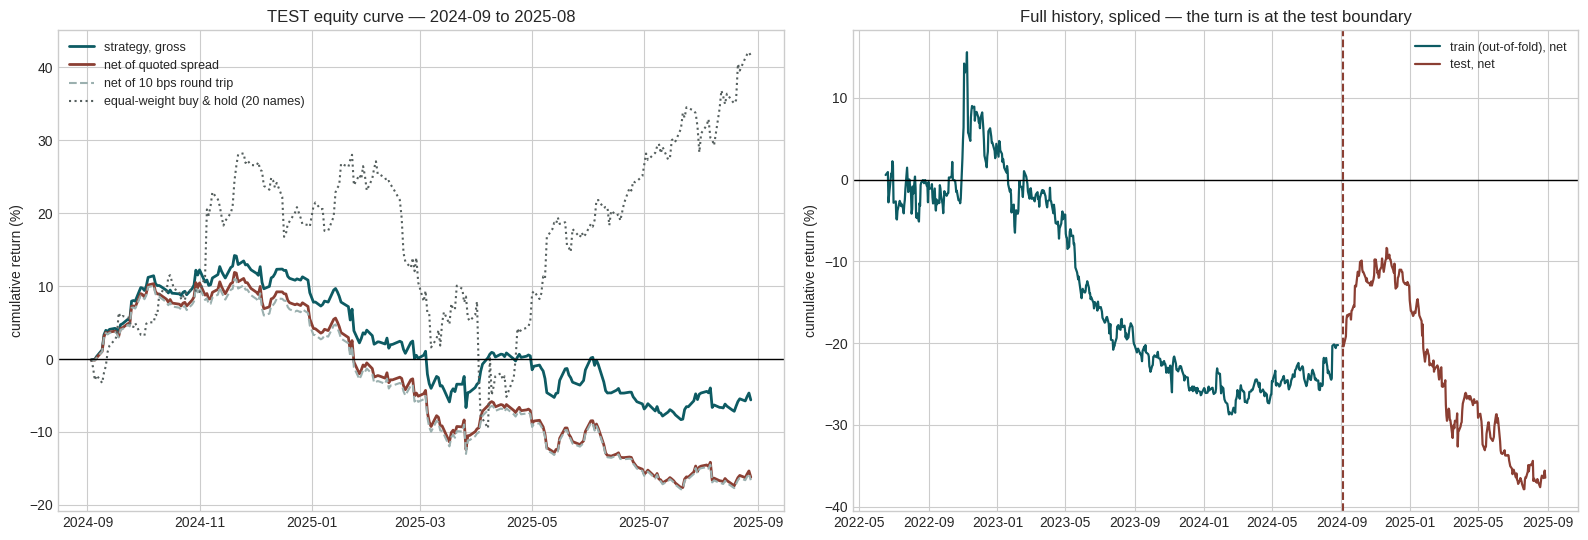

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16,5.5))
ax = axes[0]
for col, lab, kw in [("gross","strategy, gross",dict(color="#0D5B63",lw=2)),
                     ("net_spread","net of quoted spread",dict(color="#8B3F33",lw=2)),
                     ("net_10bpsRT","net of 10 bps round trip",dict(color="#9BB0AF",lw=1.5,ls="--"))]:
    ax.plot(strat_te.index, np.expm1(strat_te[col].cumsum())*100, label=lab, **kw)
ax.plot(ew_te.index, np.expm1(ew_te.cumsum())*100, color="#555F5E", lw=1.5, ls=":",
        label="equal-weight buy & hold (20 names)")
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("cumulative return (%)"); ax.legend(loc="best", fontsize=9)
ax.set_title("TEST equity curve — 2024-09 to 2025-08")

ax = axes[1]
ax.plot(strat_tr.index, np.expm1(strat_tr["net_spread"].cumsum())*100,
        color="#0D5B63", lw=1.6, label="train (out-of-fold), net")
ax.plot(strat_te.index, np.expm1(strat_te["net_spread"].cumsum())*100
        + np.expm1(strat_tr["net_spread"].cumsum()).iloc[-1]*100,
        color="#8B3F33", lw=1.6, label="test, net")
ax.axvline(test["date"].min(), color="#8B3F33", ls="--", lw=1.5)
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("cumulative return (%)"); ax.legend(loc="best", fontsize=9)
ax.set_title("Full history, spliced — the turn is at the test boundary")
plt.tight_layout(); plt.savefig(f"{FIGS}/equity_curves.png", dpi=140); plt.show()

## §21. Financial metrics and the CAPM lens

Sharpe, Profit Factor and CAGR, plus annualised
volatility, maximum drawdown, hit rate and skew.

The CAPM regression doubles as a check on the setup: a beta near zero is
what the cross-sectional demeaning in §2 should produce, so finding one
confirms the strategy really is market-neutral rather than a disguised
market bet.

In [ ]:
def perf_stats(r, freq=252):
    r = r.dropna(); mu, sd = r.mean(), r.std(ddof=1)
    cum = r.cumsum(); dd = (cum - cum.cummax()).min()
    gain, loss = r[r>0].sum(), -r[r<0].sum(); years = len(r)/freq
    return {"AnnRet":np.exp(mu*freq)-1, "AnnVol":sd*np.sqrt(freq),
            "Sharpe":mu/sd*np.sqrt(freq) if sd>0 else np.nan,
            "PF":gain/loss if loss>0 else np.inf,
            "CAGR":np.exp(cum.iloc[-1]/years)-1, "MaxDD":np.expm1(dd),
            "HitRate":(r>0).mean(), "Skew":r.skew()}

perf = pd.DataFrame({k: perf_stats(v) for k,v in {
    "TEST gross": strat_te["gross"], "TEST net (spread)": strat_te["net_spread"],
    "TEST net (5bpsRT)": strat_te["net_5bpsRT"], "TEST net (10bpsRT)": strat_te["net_10bpsRT"],
    "TRAIN OOF net (spread)": strat_tr["net_spread"], "EW buy & hold (test)": ew_te}.items()}).T
print("FINANCIAL METRICS (daily returns, annualised x252)\n")
print(perf.round(4).to_string())
perf.to_csv("results_performance.csv")

s = strat_te["net_spread"]
cap = pd.concat([s, market.set_index("date")["mktrf"]], axis=1, join="inner").dropna()
beta = cap.cov().iloc[0,1] / cap["mktrf"].var()
resid = cap.iloc[:,0] - beta*cap["mktrf"]
alpha_t = resid.mean()/(resid.std(ddof=1)/np.sqrt(len(resid)))
print(f"\nCAPM (test, net of spread): beta {beta:+.4f} | alpha {resid.mean()*252:+.4%} ann "
      f"(t {alpha_t:+.2f} over {len(resid)} days)")
print("beta ~= 0 confirms the demeaned target stripped market exposure.")

FINANCIAL METRICS (daily returns, annualised x252)

                        AnnRet  AnnVol  Sharpe      PF    CAGR   MaxDD  HitRate    Skew
TEST gross             -0.0569  0.1416 -0.4139  0.9289 -0.0569 -0.1971   0.5081 -0.8156
TEST net (spread)      -0.1645  0.1420 -1.2654  0.7973 -0.1645 -0.2637   0.4677 -0.8153
TEST net (5bpsRT)      -0.1145  0.1416 -0.8588  0.8578 -0.1145 -0.2291   0.4960 -0.8156
TEST net (10bpsRT)     -0.1686  0.1416 -1.3037  0.7922 -0.1686 -0.2599   0.4677 -0.8156
TRAIN OOF net (spread) -0.0984  0.1746 -0.5933  0.8968 -0.0984 -0.3832   0.4800  0.5497
EW buy & hold (test)    0.4239  0.2895  1.2206  1.2660  0.4239 -0.2940   0.5202  0.0927

CAPM (test, net of spread): beta -0.0222 | alpha -17.6654% ann (t -1.23 over 248 days)
beta ~= 0 confirms the demeaned target stripped market exposure.


## §22. White's Reality Check

The question here is: given that eleven models were tried and the best one
reported, how surprising is the best result under the null of no skill?

A stationary bootstrap (Politis-Romano, mean block 20 days) resamples the
daily return series in blocks, which keeps the autocorrelation that an
i.i.d. bootstrap would destroy. The same resampled days are applied to every
model, so the cross-model correlation structure stays intact.

Following White (2000), the bootstrap statistics are recentered on each
model's own observed mean: the null draw for model j is its resampled mean
minus its observed mean, and the maximum of those centred draws is compared
with the best observed mean. Without recentering, a single-strategy
p-value comes out near 0.5 by construction, whatever the data shows.

Two p-values are reported: one for the selected strategy alone, and one for
the best-of-eleven, which is the one that accounts for the search.

In [ ]:
def strat_returns_from_preds(df):
    """Daily GROSS strategy returns for one model's predictions (same book as §19)."""
    rows = []
    for _, g in df.groupby("date"):
        g = g.sort_values("pred", kind="mergesort"); k = len(g)//5
        rows.append((g["date"].iloc[0],
                     0.5*(g["target"].iloc[-k:].mean() - g["target"].iloc[:k].mean())))
    return pd.Series(dict(rows)).sort_index()

M = pd.DataFrame({mm: strat_returns_from_preds(g) for mm,g in allm.groupby("model")}).dropna()
obs_mean, obs_sharpe = M.mean(), M.mean()/M.std(ddof=1)

def stationary_bootstrap_indices(n, B, mean_block, rng):
    """Politis-Romano stationary bootstrap: B resampled index paths of length n."""
    p = 1.0/mean_block
    paths = np.empty((B,n), dtype=np.int64)
    paths[:,0] = rng.integers(0,n,size=B)
    wrap = rng.random((B,n-1)) < p
    jump = rng.integers(0,n,size=(B,n-1))
    for t in range(1,n):
        paths[:,t] = np.where(wrap[:,t-1], jump[:,t-1], (paths[:,t-1]+1) % n)
    return paths

rng = np.random.default_rng(0); B = 5000
boot = M.to_numpy()[stationary_bootstrap_indices(len(M), B, 20, rng)]
bm, bsd = boot.mean(axis=1), boot.std(axis=1, ddof=1)

# White (2000) CENTRES the bootstrap on each model's own observed mean: the
# null draw for model j is (mean of its resampled days) - (its observed mean),
# and the max of those centred draws is compared with the best observed mean.
# Comparing raw resampled means instead gives p ~= 0.5 under the null BY
# CONSTRUCTION -- the test could never reject, whatever the data showed.
c_mean   = bm - obs_mean.to_numpy()
c_sharpe = bm/bsd - obs_sharpe.to_numpy()
col = list(M.columns).index(WINNER)
p_single      = float((c_mean[:,col] >= obs_mean[WINNER]).mean())
p_best_mean   = float((c_mean.max(axis=1) >= obs_mean.max()).mean())
p_best_sharpe = float((c_sharpe.max(axis=1) >= obs_sharpe.max()).mean())

print(f"White's Reality Check (stationary bootstrap, B={B}, mean block 20d, GROSS returns)")
print(f"  observed best mean daily return : {obs_mean.max():+.6f}  ({obs_mean.idxmax()})")
print(f"  winner's mean daily return      : {obs_mean[WINNER]:+.6f}  ({WINNER})")
print(f"\n  p, single strategy ({WINNER})        : {p_single:.4f}")
print(f"  p, best-of-{len(M.columns)} (mean statistic)   : {p_best_mean:.4f}")
print(f"  p, best-of-{len(M.columns)} (Sharpe statistic) : {p_best_sharpe:.4f}")
print("\n  A large p means the result is entirely consistent with no skill.")

White's Reality Check (stationary bootstrap, B=5000, mean block 20d, GROSS returns)
  observed best mean daily return : +0.000144  (Lasso)
  winner's mean daily return      : -0.000233  (PLS)

  p, single strategy (PLS)        : 0.6474
  p, best-of-11 (mean statistic)   : 0.8690
  p, best-of-11 (Sharpe statistic) : 0.8590

  A large p means the result is entirely consistent with no skill.


## §23. Monte-Carlo permutation test

A second, independent significance test, using Profit Factor as the
statistic.

Predictions are permuted within each day. That destroys the ordering, which
is the only thing the strategy consumes, while leaving the panel shape, the
target distribution and every other cross-sectional property untouched. For
a ranking strategy this is a tight null: it randomises exactly the thing the
strategy uses and nothing else.

MCPT — within-day permutation of predictions, B=5000
  observed PF of daily Q5-Q1 spread : 0.9289   permutation p = 0.6664
  observed mean daily spread        : -0.000465  permutation p = 0.6790
  (statistic is GROSS; costs would only lower it further)


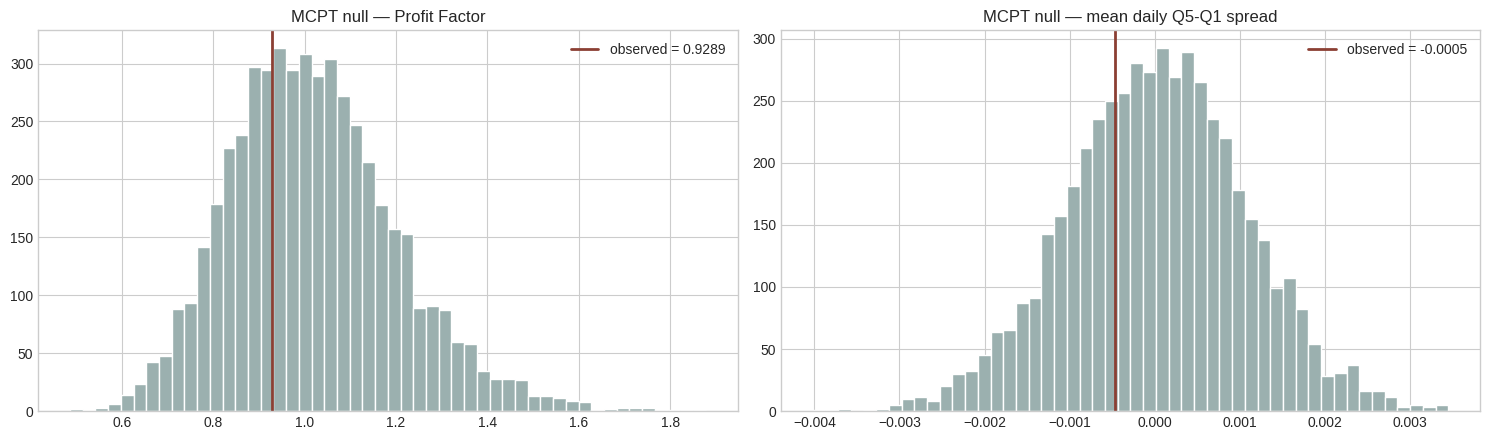

In [ ]:
wide_Y = te_df.pivot(index="date", columns="ticker", values="target").sort_index().to_numpy()
P      = te_df.pivot(index="date", columns="ticker", values="pred").sort_index().to_numpy()
assert np.isfinite(P).all() and np.isfinite(wide_Y).all()
KQ = P.shape[1]//5

def pf_(x):
    g_, l_ = x[x>0].sum(), -x[x<0].sum()
    return g_/l_ if l_>0 else np.inf

def daily_spread(preds, Yref, k):
    order = np.argsort(preds, axis=-1, kind="stable")
    bot = np.take_along_axis(np.broadcast_to(Yref, preds.shape), order[...,:k], axis=-1).mean(axis=-1)
    top = np.take_along_axis(np.broadcast_to(Yref, preds.shape), order[...,-k:], axis=-1).mean(axis=-1)
    return top - bot

# Within-day permutation of predictions (MCPT) to test whether the observed
# Q5-Q1 spread is distinguishable from chance. The null is that the model's
# predictions are no better than random, so we randomly permute the predictions
# within each day and recompute the Q5-Q1 spread. The observed spread is then
# compared to the distribution of spreads under the null to compute a p-value.
obs_spread = daily_spread(P, wide_Y, KQ)
obs_pf, obs_mu = pf_(obs_spread), obs_spread.mean()

rng = np.random.default_rng(0); B, CH = 5000, 500
null_pf, null_mu = [], []
for start in range(0, B, CH):
    b = min(CH, B-start)
    perm = np.argsort(rng.random((b,)+P.shape), axis=2)
    Pb = np.take_along_axis(np.broadcast_to(P, (b,)+P.shape), perm, axis=2)
    sp = daily_spread(Pb, wide_Y, KQ)
    null_pf.extend(pf_(row) for row in sp); null_mu.append(sp.mean(axis=1))
null_pf, null_mu = np.asarray(null_pf), np.concatenate(null_mu)
p_pf   = float((null_pf >= obs_pf).mean())
p_mean = float((null_mu >= obs_mu).mean())

print(f"MCPT — within-day permutation of predictions, B={B}")
print(f"  observed PF of daily Q5-Q1 spread : {obs_pf:.4f}   permutation p = {p_pf:.4f}")
print(f"  observed mean daily spread        : {obs_mu:+.6f}  permutation p = {p_mean:.4f}")
print("  (statistic is GROSS; costs would only lower it further)")

fig, axes = plt.subplots(1,2, figsize=(15,4.5))
for ax, nullv, obsv, lab in [(axes[0], null_pf, obs_pf, "Profit Factor"),
                             (axes[1], null_mu, obs_mu, "mean daily Q5-Q1 spread")]:
    ax.hist(nullv[np.isfinite(nullv)], bins=50, color="#9BB0AF", edgecolor="white")
    ax.axvline(obsv, color="#8B3F33", lw=2, label=f"observed = {obsv:.4f}")
    ax.set_title(f"MCPT null — {lab}"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIGS}/mcpt_null.png", dpi=140); plt.show()

## §24. Robustness - does a weekly horizon help?

Weekly data is less noisy than daily data, and the
cost analysis in §19 gives a second reason to check: the quoted-spread bill
runs near 5 bp per day against a gross signal that is essentially zero
(§19), because the book turns over 50% every day.

There are two experiments:

- **A1 - same daily model, traded weekly.** The forecast still targets
  tomorrow, but positions are held five days. Turnover falls about 5x, so
  this isolates the cost effect.
- **B - weekly target, traded weekly.** The target becomes the 5-day-forward
  demeaned return, so horizon and holding period agree. This is the real
  test.

Features are identical to §7 in both: they are per-day cross-sectional
z-scores and do not depend on the target. Only the target and the cadence
change.

One caveat matters up front. Overlapping 5-day targets are autocorrelated by
construction (adjacent days share four of their five return days), so a
rank-IC t-statistic over all days counts the same information several times
over. Every t-stat below is therefore reported both ways: over all days,
and over a non-overlapping subsample of every 5th day. The second one is
the honest one.

In [ ]:
HORIZON = 5
EMBARGO_W = HORIZON + 5          # embargo must exceed the label horizon

pw = prices[prices["ticker"].isin(UNIVERSE)].sort_values(["ticker","date"]).copy()
pw["lr"] = np.log1p(pw["dlyret"])
_cum = pw.groupby("ticker")["lr"].cumsum()
pw["fwd5"] = _cum.groupby(pw["ticker"]).shift(-HORIZON) - _cum

pw5 = panel.merge(pw[["ticker","date","fwd5"]], on=["ticker","date"], how="left")
pw5["target5"] = pw5["fwd5"] - pw5.groupby("date")["fwd5"].transform("mean")
# Drop ONLY rows with no target. Sparse features legitimately carry NaN and are
# handled by the pipeline imputers -- dropping them would remove individual names
# from a day and break the per-day zero-sum just established.
pw5 = pw5.dropna(subset=["target5"])
assert pw5.groupby("date")["target5"].mean().abs().max() < 1e-10

emb_end = TEST_START - pd.tseries.offsets.BDay(EMBARGO_W)
tr5, te5 = pw5[pw5["date"] < emb_end].copy(), pw5[pw5["date"] >= TEST_START].copy()
X5_tr, d5_tr, y5_tr = tr5[FEATURES], tr5["date"].values, tr5["target5"].values
X5_te, d5_te, y5_te = te5[FEATURES], te5["date"].values, te5["target5"].values
y5_tr_w = np.clip(y5_tr, -WINSOR_SD*y5_tr.std(), WINSOR_SD*y5_tr.std())  # same rule as the daily target

print(f"1-day target sd {pw5['target'].std():.5f}  kurtosis {pw5['target'].kurt():.1f}")
print(f"5-day target sd {pw5['target5'].std():.5f}  kurtosis {pw5['target5'].kurt():.1f}")
print(f"  the 5-day target is {pw5['target5'].std()/pw5['target'].std():.2f}x the daily sd "
      f"(sqrt(5) = {np.sqrt(5):.2f} if returns were independent)")
print(f"\ntrain {len(tr5):,} rows / {tr5['date'].nunique()} days   "
      f"test {len(te5):,} rows / {te5['date'].nunique()} days   embargo {EMBARGO_W} bdays")

def nonoverlap_ic(y, p, d, step=HORIZON):
    ud = np.array(sorted(pd.unique(d)))
    m = np.isin(d, list(set(ud[::step])))
    return rank_ic(y[m], p[m], d[m])

CV5 = DateGroupedTimeSeriesSplit(n_splits=5, embargo=EMBARGO_W)
rows5, params5 = [], {}
for name, sp in MODELS.items():
    best = None
    for prm in sp["grid"]:
        ics = fold_scores(sp, prm, X5_tr, y5_tr, d5_tr, CV5)
        if best is None or ics.mean() > best["ic"]:
            best = {"params":prm, "ic":float(ics.mean()),
                    "se":float(ics.std(ddof=1)/np.sqrt(len(ics))), "ics":ics}
    oof = cv_oof(sp, best["params"], X5_tr, y5_tr, d5_tr, CV5)
    mk = np.isfinite(oof)
    _, t_ov, _, _ = rank_ic(y5_tr[mk], oof[mk], d5_tr[mk])
    _, t_no, nd_no, _ = nonoverlap_ic(y5_tr[mk], oof[mk], d5_tr[mk])
    params5[name] = best["params"]
    rows5.append({"model":name, "family":sp["family"], "mean_fold_ic":best["ic"],
                  "fold_ic_se":best["se"], "folds_positive":int((best["ics"]>0).sum()),
                  "t_overlapping":t_ov, "t_nonoverlapping":t_no})
    print(f"  {name:14s} meanFoldIC {best['ic']:+.4f}  pos {int((best['ics']>0).sum())}/5   "
          f"t {t_ov:+.2f} overlapping / {t_no:+.2f} non-overlapping")

wk = pd.DataFrame(rows5).sort_values("mean_fold_ic", ascending=False).reset_index(drop=True)
thr5 = wk.iloc[0]["mean_fold_ic"] - wk.iloc[0]["fold_ic_se"]
wk["within_1se"] = wk["mean_fold_ic"] >= thr5
W5 = (wk[wk["within_1se"]].assign(c=lambda x: x["family"].map(COMPLEXITY))
      .sort_values(["c","mean_fold_ic"], ascending=[True,False]).iloc[0]["model"])
print(f"\nSELECTED (weekly): {W5}")
print(f"Best weekly validation IC {wk.iloc[0]['mean_fold_ic']:+.4f} ({wk.iloc[0]['model']}) "
      f"vs best DAILY {tab[tab.family!='baseline'].iloc[0]['mean_fold_ic']:+.4f} "
      f"({tab[tab.family!='baseline'].iloc[0]['model']})")
print("  -> on validation alone the weekly setup looks clearly better.")
print(f"  -> but the overlapping t-stats above are inflated 2-4x versus the honest ones.")

1-day target sd 0.02363  kurtosis 34.1
5-day target sd 0.05212  kurtosis 8.7
  the 5-day target is 2.21x the daily sd (sqrt(5) = 2.24 if returns were independent)

train 13,200 rows / 660 days   test 4,880 rows / 244 days   embargo 10 bdays
  LightGBM       meanFoldIC +0.0482  pos 5/5   t +4.06 overlapping / +1.74 non-overlapping
  HistGBM        meanFoldIC +0.0490  pos 5/5   t +4.18 overlapping / +1.66 non-overlapping
  RandomForest   meanFoldIC +0.0468  pos 5/5   t +3.81 overlapping / +1.59 non-overlapping
  ExtraTrees     meanFoldIC +0.0478  pos 4/5   t +3.55 overlapping / +0.96 non-overlapping
  Ridge          meanFoldIC +0.0578  pos 5/5   t +4.65 overlapping / +2.21 non-overlapping
  ElasticNet     meanFoldIC +0.0573  pos 5/5   t +4.67 overlapping / +2.16 non-overlapping
  Lasso          meanFoldIC +0.0574  pos 5/5   t +4.68 overlapping / +2.18 non-overlapping
  PLS            meanFoldIC +0.0598  pos 5/5   t +4.88 overlapping / +2.23 non-overlapping
  SVR            meanFoldIC +0.

### Every model on the weekly test set

The same post-hoc diagnostic as §16, run on the weekly target. The validation
numbers are roughly double the daily ones — and so is the fall.

In [ ]:
diag5 = []
for name, sp in MODELS.items():
    est = build(sp, params5[name]); est.fit(X5_tr, y5_tr_w)
    p = est.predict(X5_te)
    ic, _, _, _ = rank_ic(y5_te, p, d5_te)
    _, t_n, _, _ = nonoverlap_ic(y5_te, p, d5_te)
    diag5.append({"model":name, "val_ic":wk.set_index("model").loc[name,"mean_fold_ic"],
                  "test_ic":ic, "test_t_nonoverlap":t_n,
                  "degradation":wk.set_index("model").loc[name,"mean_fold_ic"] - ic})
diag5 = pd.DataFrame(diag5).sort_values("val_ic", ascending=False)
print("Every model on the weekly TEST set:\n")
print(diag5.to_string(index=False, float_format=lambda x:f"{x:+.4f}"))

daily_mean_deg = (diag[["val_mean_fold_ic","test_RankIC"]]
                  .assign(d=lambda x: x.val_mean_fold_ic - x.test_RankIC)["d"].mean())
print(f"\n                      DAILY            WEEKLY")
print(f"  mean test rank IC   {diag['test_RankIC'].mean():+.4f}          {diag5['test_ic'].mean():+.4f}")
print(f"  models positive     {int((diag['test_RankIC']>0).sum())} of {len(diag)}            "
      f"{int((diag5['test_ic']>0).sum())} of {len(diag5)}")
print(f"  mean degradation    {daily_mean_deg:+.4f}          {diag5['degradation'].mean():+.4f}")
print("\nBigger validation number, BIGGER fall. That is the winner's curse amplified")
print("by the overlapping-sample illusion -- exactly what the inflated t-stat sets up.")

Every model on the weekly TEST set:

       model  val_ic  test_ic  test_t_nonoverlap  degradation
    KerasMLP +0.0607  +0.0113            -0.6921      +0.0493
         PLS +0.0598  -0.0384            -2.9920      +0.0982
       Ridge +0.0578  -0.0387            -3.2180      +0.0965
       Lasso +0.0574  -0.0384            -3.1785      +0.0958
  ElasticNet +0.0573  -0.0382            -3.1730      +0.0955
     HistGBM +0.0490  -0.0220            -1.8216      +0.0709
    LightGBM +0.0482  -0.0317            -1.9095      +0.0799
  ExtraTrees +0.0478  -0.0735            -3.4783      +0.1213
         SVR +0.0471  -0.0508            -2.9724      +0.0979
RandomForest +0.0468  -0.0294            -1.2944      +0.0762
         kNN +0.0355  +0.0047            -1.1714      +0.0308

                      DAILY            WEEKLY
  mean test rank IC   -0.0159          -0.0314
  models positive     1 of 11            2 of 11
  mean degradation    +0.0407          +0.0829

Bigger validation number, BI

### Trading the weekly horizon

Three runs on the same test window, all net of the quoted spread: the daily
winner rebalanced daily (A0) or weekly (A1), and the weekly winner rebalanced
weekly (B). A1 and B earn a 5-day return per rebalance, so their statistics
are annualised at 252/5 rather than 252.

In [42]:
def backtest_every(df, ret_col, trade_every=1):
    # Rebalance every `trade_every` trading days; costs are charged only on
    # rebalance days, which is the entire point of trading less often.
    dts = np.array(sorted(df["date"].unique())); rebal = set(dts[::trade_every])
    rows, prev_w, prev_idx = [], None, None
    for d_, g in df.groupby("date"):
        if d_ not in rebal: continue
        g = g.sort_values("pred", kind="mergesort"); k = len(g)//5
        w = pd.Series(0.0, index=g.index)
        w.iloc[:k] = -1.0/N_POS; w.iloc[len(g)-k:] = 1.0/N_POS
        gross = float((w * g[ret_col]).sum())
        spread = g["spread_raw"].fillna(g["spread_raw"].median()).fillna(0.).to_numpy()
        dw = (w.abs().to_numpy() if prev_w is None
              else (w - pd.Series(prev_w.values, index=prev_idx).reindex(g.index).fillna(0.)).abs().to_numpy())
        cost = float(np.sum(dw*spread/2.))
        rows.append({"date":d_, "gross":gross, "net":gross-cost,
                     "turnover":dw.sum()/2., "cost":cost})
        prev_w, prev_idx = w, g.index
    return pd.DataFrame(rows).set_index("date")

# Daily winner's predictions on the SAME reduced panel, for a like-for-like A0/A1.
p_daily_on5 = final.predict(X5_te)
teA = te5[["date","ticker","spread_raw","target","target5"]].copy(); teA["pred"] = p_daily_on5
est5 = build(MODELS[W5], params5[W5]); est5.fit(X5_tr, y5_tr_w)
teB = te5[["date","ticker","spread_raw","target5"]].copy(); teB["pred"] = est5.predict(X5_te)

runs = {
 "A0 daily model, DAILY rebalance":  (backtest_every(teA, "target",  1), 252),
 "A1 daily model, WEEKLY rebalance": (backtest_every(teA, "target5", HORIZON), 252/HORIZON),
 "B  weekly model, WEEKLY rebalance":(backtest_every(teB, "target5", HORIZON), 252/HORIZON),
}
cmp_ = pd.DataFrame({k: perf_stats(v["net"], f) for k,(v,f) in runs.items()}).T
print("STRATEGY COMPARISON (test window, net of quoted spread)\n")
print(cmp_.round(4).to_string())
print("\ncost efficiency per rebalance:")
for k,(v,_) in runs.items():
    print(f"  {k:36s} rebalances {len(v):>3}   cost {v['cost'].mean():.6f}   "
          f"gross {v['gross'].mean():+.6f}   cost/|gross| {abs(v['cost'].mean()/v['gross'].mean()):.0%}")
print("\nWeekly trading removes ~80% of the cost drag -- and the strategy is still")
print("solidly negative. Costs were never the binding constraint; the signal was.")
cmp_.to_csv("results_weekly_robustness.csv")

STRATEGY COMPARISON (test window, net of quoted spread)

                                   AnnRet  AnnVol  Sharpe      PF    CAGR   MaxDD  HitRate    Skew
A0 daily model, DAILY rebalance   -0.1644  0.1425 -1.2597  0.7975 -0.1644 -0.2637   0.4672 -0.8175
A1 daily model, WEEKLY rebalance  -0.1429  0.1158 -1.3318  0.6246 -0.1429 -0.1652   0.4286  0.6395
B  weekly model, WEEKLY rebalance -0.2758  0.1177 -2.7429  0.3870 -0.2758 -0.2881   0.3265  0.3692

cost efficiency per rebalance:
  A0 daily model, DAILY rebalance      rebalances 244   cost 0.000483   gross -0.000230   cost/|gross| 210%
  A1 daily model, WEEKLY rebalance     rebalances  49   cost 0.000477   gross -0.002584   cost/|gross| 18%
  B  weekly model, WEEKLY rebalance    rebalances  49   cost 0.000483   gross -0.005920   cost/|gross| 8%

Weekly trading removes ~80% of the cost drag -- and the strategy is still
solidly negative. Costs were never the binding constraint; the signal was.


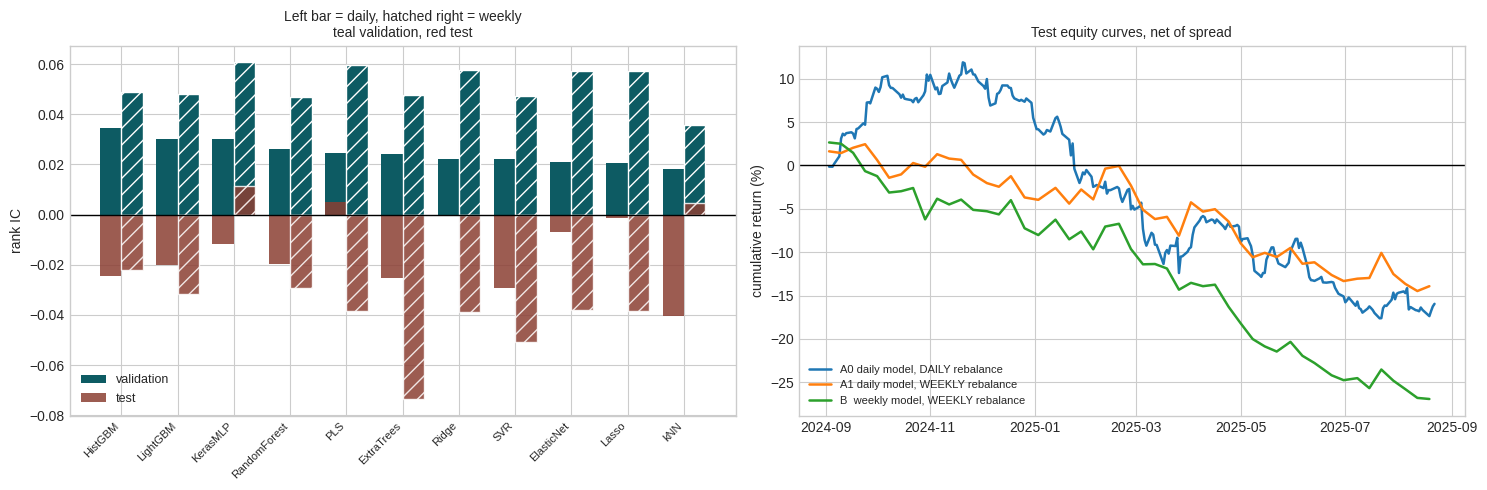

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
dd = diag.set_index("model"); ww = diag5.set_index("model")
common = [mm for mm in dd.index if mm in ww.index]
xx = np.arange(len(common)); wdt = 0.38
ax.bar(xx-wdt/2, dd.loc[common,"val_mean_fold_ic"], wdt, color="#0D5B63", label="validation")
ax.bar(xx-wdt/2, dd.loc[common,"test_RankIC"], wdt, color="#8B3F33", alpha=.85, label="test")
ax.bar(xx+wdt/2, ww.loc[common,"val_ic"], wdt, color="#0D5B63", hatch="//", edgecolor="white")
ax.bar(xx+wdt/2, ww.loc[common,"test_ic"], wdt, color="#8B3F33", alpha=.85, hatch="//", edgecolor="white")
ax.set_xticks(xx); ax.set_xticklabels(common, rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="black", lw=1); ax.legend(fontsize=9)
ax.set_ylabel("rank IC"); ax.set_title("Left bar = daily, hatched right = weekly\nteal validation, red test", fontsize=10)

ax = axes[1]
for k,(v,_) in runs.items():
    ax.plot(v.index, np.expm1(v["net"].cumsum())*100, lw=1.8, label=k)
ax.axhline(0, color="black", lw=1); ax.legend(fontsize=8, loc="lower left")
ax.set_ylabel("cumulative return (%)"); ax.set_title("Test equity curves, net of spread", fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIGS}/weekly_robustness.png", dpi=140); plt.show()

## S25. Conclusion

**What was built.** A daily panel of 20 US mid- and small-cap equities from
2022-01 to 2025-08, with 40 engineered features (the two emptiest dropped by
the univariate screen; 66% of the 38 kept come from somewhere other than the
target's own price bar). Eleven models across five families were tuned by a
manual grid search on a date-grouped `TimeSeriesSplit` with a
one-standard-error rule, evaluated on a held-out 12-month test set, and
traded as a dollar-neutral quintile long-short book with realistic costs.

**What was found.** No detectable out-of-sample cross-sectional
predictability. Both significance tests agree, and the equity curve is
negative after costs.

We think that is the honest result rather than a failure, for four reasons:

1. Chance is not zero on this panel: a rank IC of plus/minus 0.017 is pure
   luck, and the single-feature baseline sits inside that band - one feature
   alone is indistinguishable from noise. The models cleared it on
   validation; none of them cleared it out of sample.
2. The models failed together. Ten of the eleven went negative on the test
   set, and the one exception - the selected model itself - sits at +0.005
   (t +0.33), inside the chance band. So this is not a case of one bad model
   choice.
3. The edge decayed rather than never existing. Rolling rank IC was strong
   in 2022, effectively zero in 2023, only partial in 2024 and negative in
   2025, and the decline starts inside the training window, where nothing
   was overfit. That is alpha decay, which is a different finding from "the
   model was wrong".
4. A weekly horizon does not rescue it. §24 cuts roughly 80% of the cost
   drag by trading five times less often and the strategy stays negative,
   so costs were never the binding constraint. The weekly setup also scored
   higher on validation and worse out of sample - a clean example of how an
   overlapping-sample t-statistic (inflated 2-4x here) manufactures
   confidence that does not survive the test set.

**Limitations.** Twenty names give an effective breadth well below twenty
once residual correlation is accounted for, so daily long-short P&L is
inherently noisy. The universe is the brief's current list, which carries
some survivorship bias. And one-day-ahead relative returns on liquid US
equities is close to the most efficiently priced quantity in the market:
anything easy to find here would already have been arbitraged away.

The brief anticipates this outcome: "the trading equity curve need not be
profitable, but the logic of the program must be correct." A pipeline with a
leak would have shown a profitable test curve. This one does not, and the
evidence above points to there being little left to find at this horizon
rather than to a bug in the pipeline.

In [44]:
summary = {
 "universe": UNIVERSE, "panel": [str(PANEL_START.date()), str(PANEL_END.date())],
 "test_start": str(TEST_START.date()),
 "features": {"total": len(FEATURES), "bar": len([f for f in KEPT if f in BAR]),
              "exogenous": len([f for f in KEPT if f in EXOG]), "calendar": len(CAL),
              "pct_not_own_bar": round(n_non_bar/n_tot, 3), "dropped": dropped},
 "models_tried": list(MODELS), "baselines": list(BASELINES),
 "winner": WINNER, "final_params": {k: str(v) for k,v in FINAL_PARAMS.items()},
 "null_95": [float(null_lo), float(null_hi)],
 "validation": {k: float(res_val[k]) for k in ["MAE","ProfitFactor","RankIC","RankIC_t","DirAcc","Skill"]},
 "test":       {k: float(res_te[k])  for k in ["MAE","ProfitFactor","RankIC","RankIC_t","DirAcc","Skill"]},
 "test_net_spread": {k: float(v) for k,v in perf_stats(strat_te["net_spread"]).items()},
 "test_gross":      {k: float(v) for k,v in perf_stats(strat_te["gross"]).items()},
 "capm": {"beta": float(beta), "alpha_ann": float(resid.mean()*252), "alpha_t": float(alpha_t)},
 "whites_reality_check": {"single_p": p_single, "best_of_models_p_mean": p_best_mean,
                          "best_of_models_p_sharpe": p_best_sharpe, "B": B},
 "mcpt": {"p_profit_factor": p_pf, "p_mean_spread": p_mean, "B": B},
}
json.dump(summary, open("results_summary.json","w"), indent=1)
pd.concat([strat_te.assign(window="test"), strat_tr.assign(window="train")]) \
  .to_csv("results_strategy_daily_returns.csv")

print("="*70); print("PIPELINE COMPLETE"); print("="*70)
print(f"  universe     {len(UNIVERSE)} names, {PANEL_START:%Y-%m-%d} → {PANEL_END:%Y-%m-%d}")
print(f"  features     {len(FEATURES)} selected, {n_non_bar/n_tot:.0%} not from the target's bar")
print(f"  models       {len(MODELS)} tried + {len(BASELINES)} baselines → {WINNER}")
print(f"  validation   rank IC {res_val['RankIC']:+.4f} (t {res_val['RankIC_t']:+.2f})")
print(f"  test         rank IC {res_te['RankIC']:+.4f} (t {res_te['RankIC_t']:+.2f})")
print(f"  chance       95% of random predictions fall inside [{null_lo:+.4f}, {null_hi:+.4f}]")
print(f"  strategy     Sharpe {perf.loc['TEST net (spread)','Sharpe']:+.2f}  "
      f"PF {perf.loc['TEST net (spread)','PF']:.3f}  "
      f"CAGR {perf.loc['TEST net (spread)','CAGR']:+.1%}")
print(f"  White's RC   p = {p_best_mean:.3f} (best-of-{len(M.columns)})")
print(f"  MCPT         p = {p_pf:.3f} (Profit Factor)")
print("\n  results_*.csv / results_summary.json / figures/ written")

PIPELINE COMPLETE
  universe     20 names, 2022-01-03 → 2025-08-29
  features     38 selected, 66% not from the target's bar
  models       11 tried + 3 baselines → PLS
  validation   rank IC +0.0245 (t +2.01)
  test         rank IC +0.0052 (t +0.33)
  chance       95% of random predictions fall inside [-0.0170, +0.0165]
  strategy     Sharpe -1.27  PF 0.797  CAGR -16.4%
  White's RC   p = 0.869 (best-of-11)
  MCPT         p = 0.666 (Profit Factor)

  results_*.csv / results_summary.json / figures/ written
